# Consumer Financial Complaint Classification
## A Unified Analysis of CFPB Complaint Narratives

**INFO 4360 — Complex Data Analytics**  
**Group members:** Rebecca and Ketty  
**Study period:** August 2025–July 2026  
**Dataset:** CFPB consumer complaint narratives (11 financial-product categories)

### Research objective

Evaluate whether conventional supervised text classifiers, semantic-embedding similarity, or Claude zero-shot classification can most reliably assign a consumer complaint narrative to its financial-product category. The practical motivation is to support **complaint triage and routing**, while recognizing that CFPB product labels are a proxy for operational routing decisions—not verified routing outcomes.

### Analytical approach

We examine the source data and complaint language, remove exact duplicate narratives, create one stratified 70/30 train/test split, and compare all available methods on the same held-out cases. Supervised model selection uses five-fold cross-validation **on training data only**. Additional analyses examine class-level errors, sensitivity to product words, decision-margin reliability, subgroup performance, and API costs.

### Executive summary of the executed analysis

The final dataset contains **4,895 unique narratives**; **3,426** are used for training and **1,469** for testing. **TF-IDF + Linear SVM** was selected using training cross-validation and achieved **73.8% test accuracy** and **0.736 macro F1**. Cached **Claude zero-shot** predictions achieved **72.6% accuracy** and **0.724 macro F1**. The results support evaluating a **local supervised classifier with human review for uncertain cases** as an initial routing pilot, rather than assuming that a more complex or API-based approach will necessarily perform better.

> **Scope and reproducibility:** This notebook uses local computation and **previously cached** Claude outputs; it does not make new Claude API calls. Some model files and data caches are stored in the project repository and are needed for a full rerun. Reported results are descriptive of this sample, not prospective production performance.


## 0. Environment and reproducibility

### 0.1 Libraries and project configuration

All imports are collected in the cell below. The notebook requires the project `Data/` and `src/` directories, plus previously saved Claude caches for the corresponding comparisons.

In [1]:
# Notebook display, file handling, text patterns, and reproducible project paths
%matplotlib inline
import sys
import os
import re
import json
import time
import hashlib
from pathlib import Path
from collections import Counter

# Locate repository root whether VS Code starts in Notebook/ or the repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebook" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "rebecca_modelling"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Data handling and notebook tables
import numpy as np
import pandas as pd
from IPython.display import display

# Visualization: charts, heatmaps, and word clouds
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# NLP: stopwords, lemmatization, and NLTK language resources
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download(["stopwords", "wordnet"], quiet=True)

# Supervised learning: stratified validation, TF-IDF, and three classifiers
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.preprocessing import normalize
from sklearn.metrics import precision_score, recall_score
import spacy
from sentence_transformers import SentenceTransformer

# Evaluation: per-class reports, confusion matrices, and cosine similarity
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score)
from sklearn.metrics.pairwise import cosine_similarity

# Claude API and .env credentials (never display secret values); embeddings load on demand
# API calls are deliberately disabled; no Anthropic SDK or credentials are required.

# Reusable data preparation and sentiment functions from this project
from src.data_utils import load_complaints, missing_values, duplicate_narratives, TEXT_COL
from src.preprocessing import (clean_text, drop_duplicate_narratives, top_terms,
                               distinctive_terms, product_word_matrix, STOPWORDS)
from src.text_analysis import (sentiment_scores, sentiment_label, positive_word_contributions,
                               FINANCE_WORDS)

# Consistent figure styling for presentation and reporting
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0,
              rc={"axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 14,
                  "axes.labelsize": 11, "figure.facecolor": "white", "axes.facecolor": "white",
                  "grid.alpha": 0.20, "savefig.dpi": 200})
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
MAIN = sns.color_palette("deep")[0]
ACCENT = sns.color_palette("deep")[3]
pd.set_option("display.max_colwidth", 200)
print("Project root:", PROJECT_ROOT)

Project root: /Users/rebeccaquaye/Complex Data Analytics/Project/consumer-financial-complaints


### 0.2 Load the data

In [2]:
# PURPOSE: Load the project sample and create date/product helper fields.
# Load the complaint sample. load_complaints reads the CSV, parses the dates and adds
# three helper columns: month, product_short (short product names) and word_count
DATA_PATH = DATA_DIR / "cfpb_complaints_sample_2025-08_to_2026-07.csv"
# Use the shared loader so date parsing and helper columns match the EDA.
df = load_complaints(DATA_PATH)

## 1. Data exploration

### 1.1 Size and structure

A quick look at how many complaints we have, the period they cover, and the columns we will use.
Note: the 19 columns include 3 helper columns created by `load_complaints` (`month`, `product_short`, `word_count`).

In [3]:
# PURPOSE: Inspect the source schema before summarizing or modeling.
# Preview the first two rows with every column, to see what each field looks like
df.head(2)

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID,month,product_short,word_count
0,2025-11-03,Mortgage,VA mortgage,Trouble during payment process,Payment process,"b""Summary\n\nShellpoint / XXXX have created a pattern of payment re-aging, unapplied funds, and fabricated fees on my post-discharge mortgage account. Agents repeatedly invoked bankruptcy discla...",Company has responded to the consumer and the CFPB and chooses not to provide a public response,"Shellpoint Partners, LLC",TN,37066,Servicemember,Web,2025-11-03,Closed with explanation,Yes,16983019,2025-11,Mortgage,5058
1,2026-04-27,Debt or credit management,Debt settlement,Didn't provide services promised,NaN,"I am filing a complaint against Affirm regarding a consumer loan used to finance a purchase that was never full delivered. On XX/XX/year>, I entered into a financing agreement with Affirm to purch...",NaN,"Affirm Holdings, Inc",ME,049XX,Older American,Web,2026-04-27,Closed with explanation,Yes,21642170,2026-04,Debt management,351


In [4]:
# PURPOSE: Report row counts, product counts, and date coverage.
# --- Dataset size and scope ---
# Report the sample size before deduplication; the modeling set is smaller.
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")

# Date range covered by the sample (should run Aug 2025 to Jul 2026)
print(f"Complaints received: {df['Date received'].min():%b %d, %Y} to {df['Date received'].max():%b %d, %Y}")

# Number of target classes (products) and how many different companies appear
print(f"Product categories: {df['Product'].nunique()}   Companies: {df['Company'].nunique()}")

# --- Preview: first 5 complaints, showing the key columns only ---
df[["Date received", "product_short", "Issue", "word_count"]].head()

Rows: 5,000   Columns: 19
Complaints received: Aug 01, 2025 to Jul 29, 2026
Product categories: 11   Companies: 626


,Date received,product_short,Issue,word_count
0,2025-11-03,Mortgage,Trouble during payment process,5058
1,2026-04-27,Debt management,Didn't provide services promised,351
2,2026-05-19,Debt management,Confusing or misleading advertising or marketing,275
3,2025-11-29,Debt collection,False statements or representation,242
4,2026-02-09,Credit reporting,Incorrect information on your report,120


### 1.2 Missing values

In [5]:
# PURPOSE: Identify missing fields without imputing the classification target.
# Count missing values per column (only columns with at least one gap are listed)
missing_values(df)

,missing_rows,share_missing
Tags,4182,0.836
Company public response,3436,0.687
Sub-issue,1398,0.280
State,38,0.008
ZIP code,10,0.002


**Missing-data interpretation.** The original 5,000-row sample has no missing product labels or complaint narratives. However, **105 duplicate narrative rows are removed before modeling**, leaving **4,895 distinct narratives**. The largest missing-data shares concern `Tags` (83.6%), `Company public response` (68.7%), and `Sub-issue` (28.0%); these are not text-classification inputs. Missing `Tags` should not be interpreted as the absence of a demographic attribute.

### 1.3 Target distribution: our sample vs. the full database

In the full CFPB database one category dominates. We sampled the same number of complaints per product so the model learns every category, not just credit reporting.

In [6]:
# PURPOSE: Count the observed product labels in the sampled data.
# Count complaints by product (the target variable we will predict)
product_counts = df["Product"].value_counts()

product_counts

Product
Debt or credit management                                  455
Debt collection                                            455
Credit reporting or other personal consumer reports        455
Credit card                                                455
Money transfer, virtual currency, or money service         455
Checking or savings account                                455
Mortgage                                                   454
Payday loan, title loan, personal loan, or advance loan    454
Vehicle loan or lease                                      454
Prepaid card                                               454
Student loan                                               454
Name: count, dtype: int64

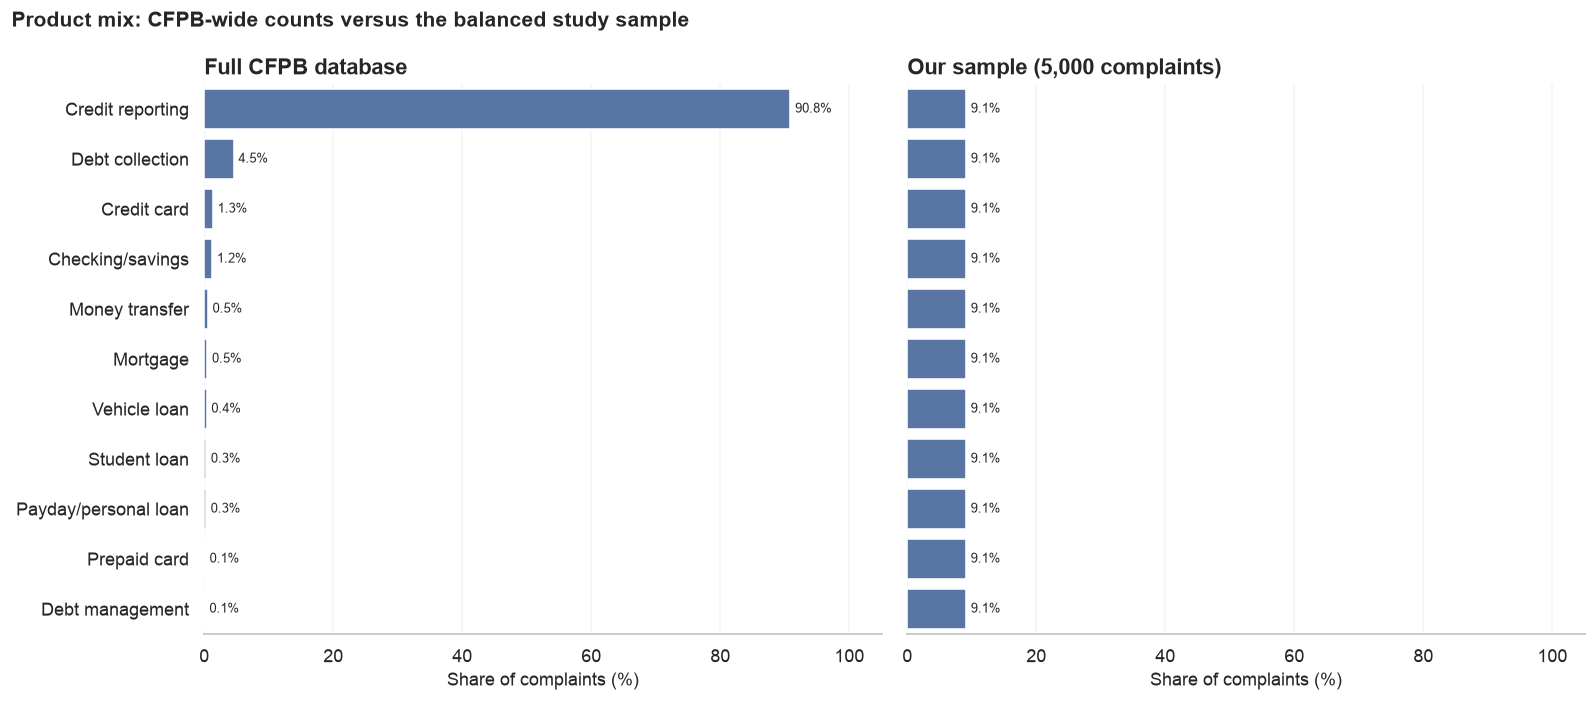

In [7]:
# PURPOSE: Compare sample class balance with the separately reported CFPB population totals.
# Product counts shown on the CFPB complaint search page (all complaints, Oct 2026)
database_counts = pd.Series({
    "Credit reporting": 6_341_482, "Debt collection": 317_439, "Credit card": 92_750,
    "Checking/savings": 85_931, "Money transfer": 38_217, "Mortgage": 32_110,
    "Vehicle loan": 24_617, "Student loan": 19_519, "Payday/personal loan": 17_907,
    "Prepaid card": 6_122, "Debt management": 4_243,
})
# Convert counts to % shares so the full database and our sample can be compared on one scale
database_share = database_counts / database_counts.sum() * 100
sample_share = df["product_short"].value_counts(normalize=True) * 100

order = database_share.sort_values().index      # same product order in both panels

shares = pd.DataFrame({"Full CFPB database": database_share,
                       "Our sample (5,000 complaints)": sample_share}).reindex(order[::-1])

# Two side-by-side bar charts: full database (left) vs. our sample (right)
# Compare the balanced sample with population totals without treating the sample as representative.
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
for ax, column in zip(axes, shares.columns):
    sns.barplot(x=shares[column], y=shares.index, color=MAIN, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)   # write the % at the end of each bar
    ax.set(xlim=(0, 105), xlabel="Share of complaints (%)", ylabel="", title=column)

fig.suptitle("Product mix: CFPB-wide counts versus the balanced study sample",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- Our sample is **balanced by design**: 454 or 455 complaints for each of the 11 products (table above).
- The real complaint stream is extremely imbalanced: credit reporting is about 91%, and the six smallest products are each under 0.5%. A model trained on raw data could score 91% accuracy by always guessing "credit reporting" and still be useless for routing.
- Because the sample is balanced, **accuracy is a fair headline metric**, and **macro F1** (which weights every product equally) shows whether small products are handled well.
- For Phase 3: a model trained on balanced data will over-predict small products when used on real traffic. We will note this and consider adjusting for real-world frequencies when interpreting results.

### 1.4 Coverage over time

In [8]:
# PURPOSE: Check monthly coverage to assess the sampling window.
# Number of complaints received in each month of the sample
per_month = df["month"].value_counts().sort_index()
print(per_month.to_string())

# Smallest count in the month x product table: if it is above 0, every product appears in every month
print(f"\nSmallest product-month cell: {pd.crosstab(df['month'], df['Product']).min().min()} complaints")

month
2025-08    418
2025-09    418
2025-10    418
2025-11    418
2025-12    418
2026-01    418
2026-02    418
2026-03    418
2026-04    418
2026-05    418
2026-06    413
2026-07    407
Freq: M

Smallest product-month cell: 37 complaints


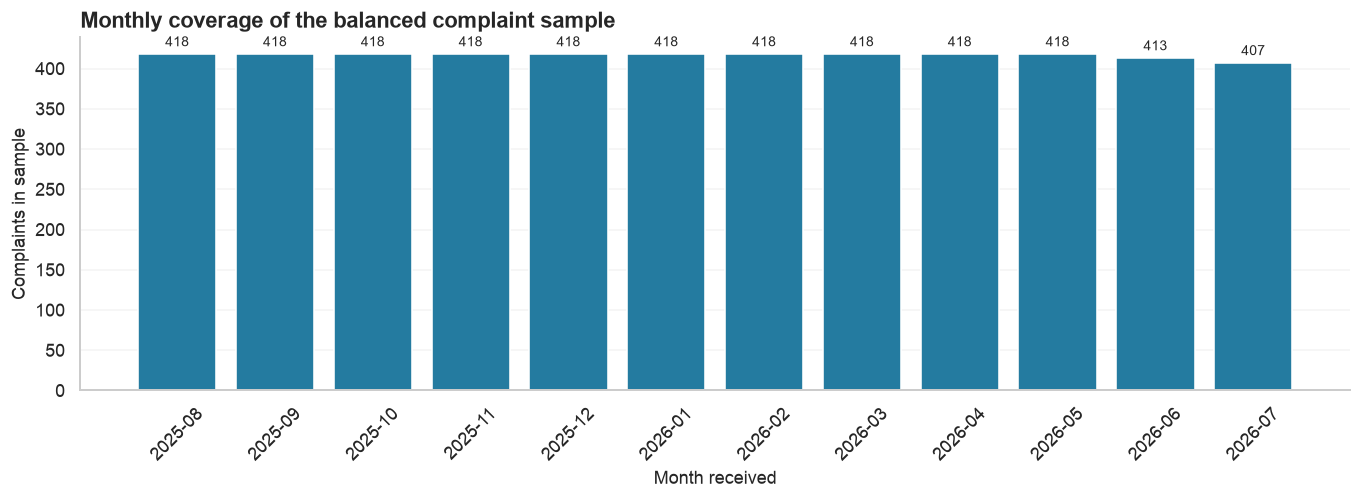

In [9]:
# PURPOSE: Plot monthly counts; this chart is not a population time trend.
# Monthly coverage chart: the sampling design, not population complaint trends.
monthly = df["month"].value_counts().sort_index()
# Plot coverage by month; near-uniform sampling should not be read as a volume trend.
fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.bar(monthly.index.astype(str), monthly.values, color="#247BA0")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set(xlabel="Month received", ylabel="Complaints in sample", title="Monthly coverage of the balanced complaint sample")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Temporal coverage.** The sample spans August 2025 through July 2026, with relatively even monthly counts (418 in most months, 413 in June, and 407 in July). The slight decrease in the final months is visible in this sample, but the notebook does **not establish its cause**. Because sampling was designed to balance months and products, these counts should not be read as real-world changes in complaint volume.

### 1.5 Complaint Narrative Length

We examine the length of the consumer complaint narratives to understand how much the amount of text varies across complaints.

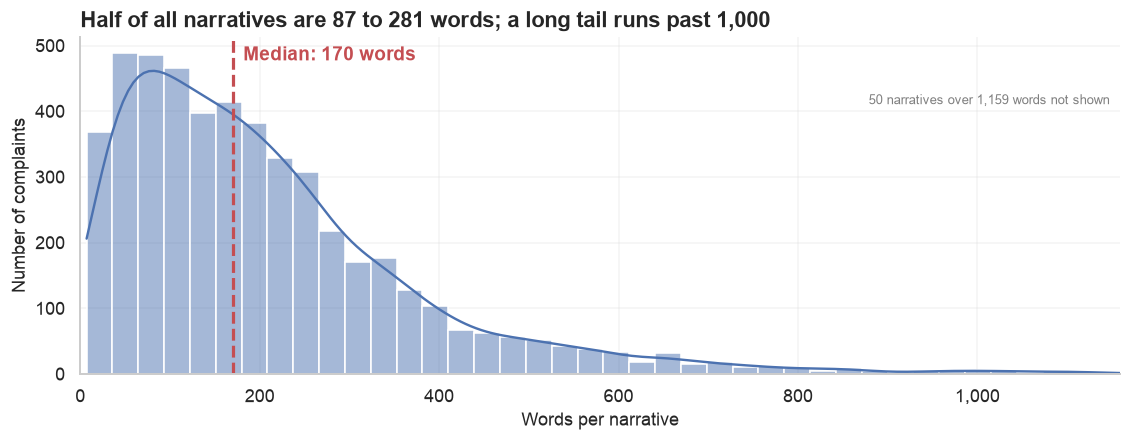

count    5000.0
mean      225.0
std       251.0
min         7.0
25%        87.0
50%       170.0
75%       281.0
max      5058.0
Under 50 words: 12%   Over 500 words: 7%


In [10]:
# PURPOSE: Summarize complaint length and visualize the right-skewed distribution.
# Number of words in each narrative (helper column created by load_complaints)
words = df["word_count"]

# Plain (linear) axis: show the chart up to the 99th percentile so the long tail
# doesn't squash the bars; the statistics below still use every complaint
cap = words.quantile(0.99)
shown = words[words <= cap]

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(shown, bins=40, color=MAIN, kde=True, ax=ax)   # bars = counts, line = smoothed shape
# Dashed line and label at the median
ax.axvline(words.median(), color=ACCENT, linewidth=2, linestyle="--")
ax.text(words.median() + cap * 0.01, ax.get_ylim()[1] * 0.93, f"Median: {words.median():.0f} words",
        color=ACCENT, fontweight="bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))   # 1,000 instead of 1000
ax.set(xlim=(0, cap), xlabel="Words per narrative", ylabel="Number of complaints",
       title="Half of all narratives are 87 to 281 words; a long tail runs past 1,000")
# Note on the chart how many long narratives fall outside the plotted range
ax.text(0.99, 0.80, f"{(words > cap).sum()} narratives over {cap:,.0f} words not shown",
        transform=ax.transAxes, ha="right", fontsize=8, color="grey")
sns.despine()
plt.tight_layout()
plt.show()

# Summary statistics on ALL narratives, plus the share of very short and very long ones
print(words.describe().round(0).to_string())
print(f"Under 50 words: {(words < 50).mean():.0%}   Over 500 words: {(words > 500).mean():.0%}")

Complaint narrative lengths are right-skewed, with most complaints containing relatively short narratives and fewer complaints having very long narratives. The median narrative is 170 words, while the mean is higher at 225 words, and the longest runs to 5,058 words. This difference reflects a smaller number of very long complaints: 7% are over 500 words, while 12% are under 50 words.

For readability, the histogram displays narratives up to the 99th percentile. The full dataset, including longer narratives, is retained for the analysis. The variation in narrative length may be important when preprocessing the text and building the classification model.

### 1.6 Data quality: redactions and template letters

In [11]:
# PURPOSE: Flag anonymization placeholders and repeated narrative templates.
# Share of narratives containing CFPB redactions (two or more X's in a row, e.g. XXXX)
has_redaction = df[TEXT_COL].str.contains(r"X{2,}")
print(f"Narratives with redacted text (XXXX): {has_redaction.mean():.0%}")

# Narratives whose text appears more than once (template letters)
dupes = duplicate_narratives(df)
extra_copies = int((dupes["copies"] - 1).sum())   # copies beyond the first one of each letter
print(f"Narratives that appear more than once: {len(dupes)}  ({extra_copies} extra copies)")
dupes.head(5)   # the five most repeated letters

Narratives with redacted text (XXXX): 82%
Narratives that appear more than once: 44  (105 extra copies)


,copies,narrative_start
0,27,There are collection accounts on my report that I believe contain inaccurate information. Under my rights pursuant to 15...
1,13,"You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit Repo..."
2,7,My rights were violated as a consumer under 15USC1681B and I need them blocked and deleted from my report ASAP...
3,7,I want to stress that I did not give written permission for these specific transactions to be included in my consumer re...
4,5,My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You have the duty to repor...


- **82% of narratives contain CFPB redactions** (`XXXX` for names, account numbers and dates). These are meaningless to a model, so the cleaning step will remove them before counting words.
- **105 rows are exact copies** of 44 template letters, mostly credit reporting disputes citing FCRA sections. If copies land in both the training and test sets, the model is tested on text it has already seen and its score is inflated. We remove the extra copies before modeling, leaving 4,895 unique narratives.

### 1.7 Example narratives (one per product)

In [12]:
# PURPOSE: Inspect reproducible examples without exposing full data in the narrative.
# Display one sample complaint narrative per product (random_state fixes the sample so it is reproducible)
sample_complaints = (
    df[["Product", "Consumer complaint narrative"]]
    .groupby("Product")
    .sample(n=1, random_state=42)
    .sort_values("Product")
)

# Print the product and the first 500 characters of its narrative
for _, row in sample_complaints.iterrows():
    print("Product:", row["Product"])
    print("Narrative:", row["Consumer complaint narrative"][:500])
    print("-" * 80)

Product: Checking or savings account
Narrative: On XX/XX/year>2025, a teller at a Chase branch store stole {$1200.00} from my cash deposit while I was having a medical emergency. I am a type XXXX XXXX  and was experiencing XXXX XXXX XXXX  at the time, not feeling well. The teller noticed something was wrong, but instead of helping me, she took advantage of my condition and shorted my deposit. 

I tried filing a complaint with Chase immediately after the incident by calling the fraud department, and again on XX/XX/year>2025. Each time I was to
--------------------------------------------------------------------------------
Product: Credit card
Narrative: - I have been unable to log into my account for almost a year. Since XX/XX/XXXX. - I attempted to log in while on the phone with a Synchrony representative who confirmed that the information I was entering was correct, yet the system continued to reject it ; no technical ticket was opened and no remedy was provided to me outside of a re

The sample complaints vary in length and writing style, but they contain language that provides clues about the financial product involved. Some name the product outright ("my mortgage account", "private student loan", "my vehicle", "Amex giftcard"), while others only point to it through context, such as a company or service name (PayPal for money transfer, Cash App Borrow for a payday loan). The mortgage example is itself about credit reporting of a late payment, so a single complaint can touch more than one product.

This supports the use of text classification for categorizing unlabeled complaints, but it also highlights a potential concern: explicit product words may make some complaints easier to classify. We will examine this further in the modeling phase as part of our leakage and sanity checks.

## 2. Text mining

### 2.1 Preparing the text

We first remove exact duplicate narratives, leaving **4,895 unique texts**. `clean_text` standardizes text for descriptive analysis and supervised TF-IDF. For word-frequency counts, a second pass removes stopwords and lemmatizes words. **All subsequent text-mining analyses use the deduplicated sample**, not the original 5,000 rows. These descriptive analyses summarize the full modeling sample; only the training portion is used for model fitting and cross-validation.

In [13]:
# PURPOSE: Remove exact duplicate narratives and create a normalized text field.
# Remove duplicate template letters, then clean every narrative
# Deduplicate before splitting so identical narratives cannot appear in both partitions.
text_df = drop_duplicate_narratives(df)                 # keep one copy of each template letter
text_df["clean"] = text_df[TEXT_COL].map(clean_text)   # cleaned text used for TF-IDF and sentiment checks
print(f"Unique narratives used for text mining: {len(text_df):,}")

# Before / after cleaning for one complaint
example = text_df.iloc[3]
print("\nBEFORE:", example[TEXT_COL][:300])
print("\nAFTER: ", example["clean"][:300])

Unique narratives used for text mining: 4,895

BEFORE: I am writing in response to your communication regarding the abovereferenced alleged debt. I dispute this debt in its entirety ( or, if applicable, I dispute the amount you claim is owed ) and request full validation under the Fair Debt Collection Practices Act ( FDCPA ), 15 U.S.C. 1692g.

Please pr

AFTER:  i am writing in response to your communication regarding the abovereferenced alleged debt i dispute this debt in its entirety or if applicable i dispute the amount you claim is owed and request full validation under the fair debt collection practices act fdcpa u s c g please provide in writing the n


In [14]:
# PURPOSE: Tokenize and lemmatize for descriptive word-frequency analysis.
# Stricter cleaning for raw word counts (stopwords removed, lemmatized)
stop_words = set(stopwords.words("english"))   # common English words such as "the", "and", "is"
lemmatizer = WordNetLemmatizer()               # reduces words to their base form ("payments" -> "payment")

# Helper: clean for counts for the analysis below.
def clean_for_counts(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Split text into individual words
    words = text.split()

    # Remove stopwords and redaction placeholders
    words = [
    word for word in words
    if word not in stop_words and not re.fullmatch(r"x+", word)
    ]

    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return " ".join(words)

# Apply stricter cleaning to unique narratives for word-frequency analysis
text_df["clean_narrative"] = text_df[TEXT_COL].apply(clean_for_counts)

### 2.2 Most common words and phrases across all complaints

We start with single words, then move to two-word phrases (bigrams), which carry more meaning.

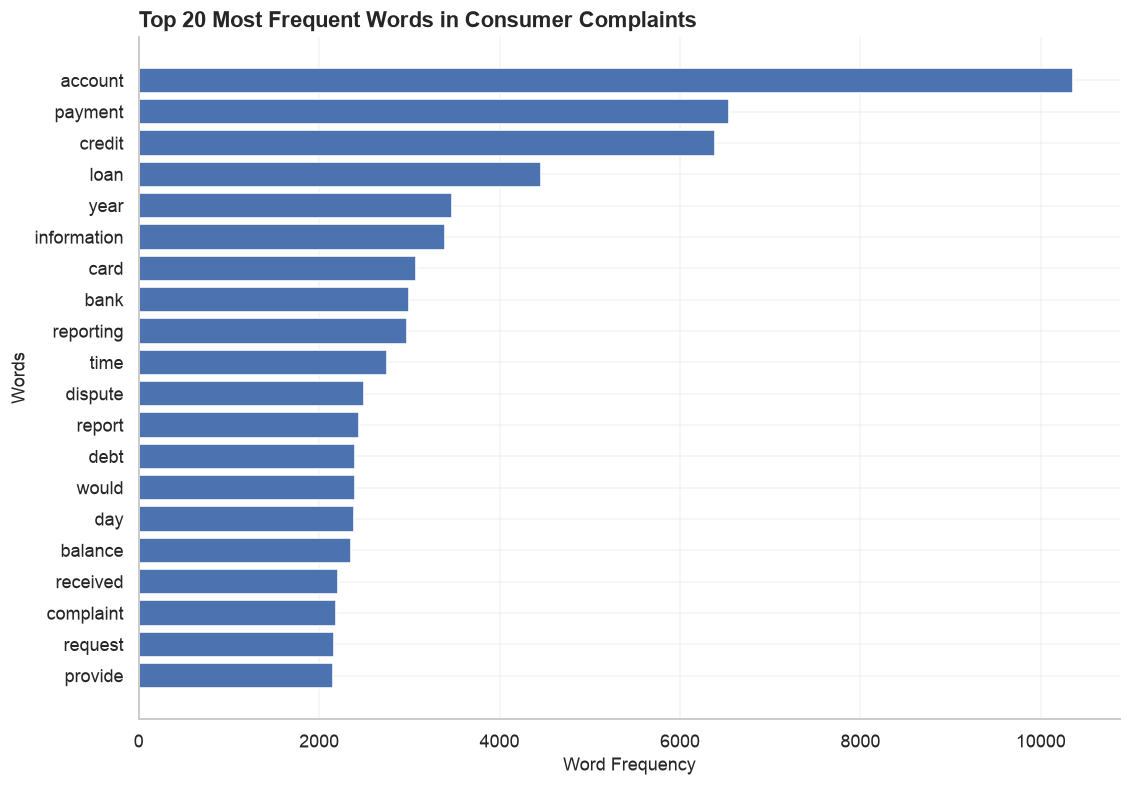

In [15]:
# PURPOSE: Rank common words after preprocessing.
# Count the most common single words across all narratives

# Combine cleaned words from unique complaint narratives
all_words = " ".join(text_df["clean_narrative"]).split()
# Count how often each word appears
word_counts = Counter(all_words)   # Counter maps each word to the number of times it appears

# Get the 20 most common words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)
# Plot the 20 most frequent words
plt.figure(figsize=(10, 7))

plt.barh(top_words["Word"], top_words["Frequency"])

plt.title("Top 20 Most Frequent Words in Consumer Complaints")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

# Display the most frequent word at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Interpretation

- **Account** is the most frequently used word, followed by **payment**, **credit**, and **loan**. These terms reflect common financial issues discussed in consumer complaints.
- Most of the frequently occurring words are general financial terms that appear across different product categories.
- Although individual words help us understand the main topics in complaints, they may not be enough to distinguish financial products. This is why we also examine bigrams and other text-mining techniques.

**Note:** This analysis uses 4,895 unique complaint narratives after removing duplicates to avoid counting repeated text multiple times.

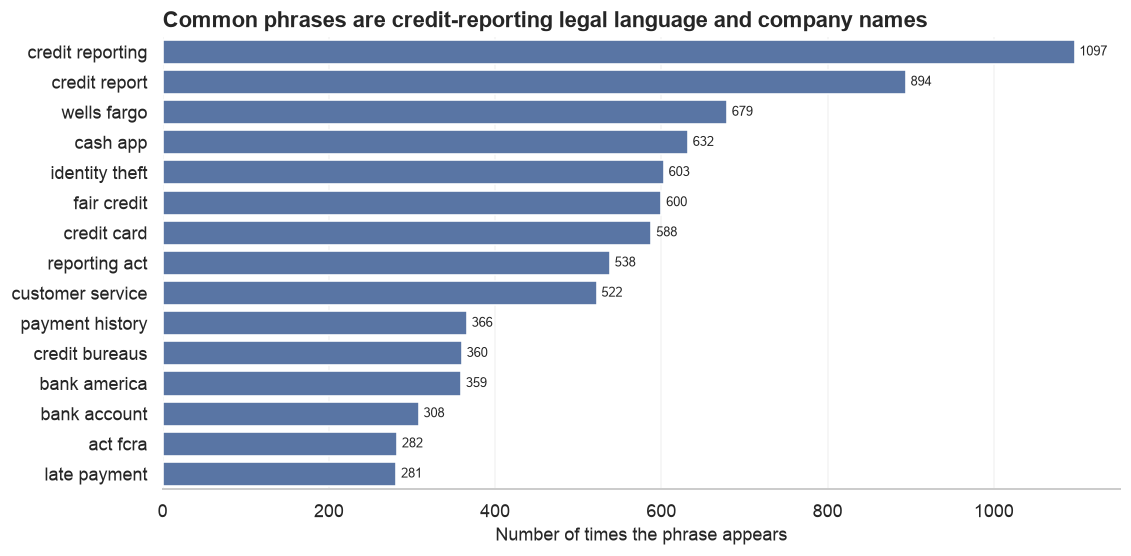

In [16]:
# PURPOSE: Count the most common two-word phrases.
# Top 15 two-word phrases across all complaints
top_phrases = top_terms(text_df["clean"], n=15, ngram_range=(2, 2))   # ngram_range=(2, 2): two-word phrases only

# Horizontal bar chart, most frequent phrase at the top
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_phrases, x="count", y="term", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=8)   # write the count at the end of each bar
ax.set(xlabel="Number of times the phrase appears", ylabel="",
       title="Common phrases are credit-reporting legal language and company names")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- The two most frequent phrases are "credit reporting" (1,097) and "credit report" (894), and several others ("fair credit", "reporting act", "act fcra") come from **legal language about the Fair Credit Reporting Act**. Consumers in several products, not only credit reporting, quote this law, so these phrases alone will not separate products cleanly.
- **Company names** are among the most common phrases: "wells fargo" (679) and "cash app" (632) rank third and fourth, and "bank america" (359) also appears. A company usually points to a product (Cash App means money transfer), so the model may lean on them. That is useful for routing at one bank, but we will check in Phase 3 that the model is not relying on company names alone.
- "Identity theft" (603 mentions) is a major theme on its own.

### 2.3 The words that distinguish each product

**Raw counts first.** The most frequent words within each product:

In [17]:
# PURPOSE: Define a reusable per-product token-frequency helper.
# Get the most common words for a product category
def get_top_words_by_product(product, n=10):

    # Select cleaned narratives for the chosen product
    product_text = text_df.loc[
        text_df["Product"] == product, "clean_narrative"
    ]

    # Combine the narratives into individual words
    words = " ".join(product_text).split()

    # Count the words
    word_counts = Counter(words)

    # Return the most frequent words
    return pd.DataFrame(
        word_counts.most_common(n),
        columns=["Word", "Frequency"]
    )


# Get the top 5 words for each product category
product_word_summary = []

# Loop through all 11 financial product categories
for product in text_df["Product"].unique():

    top_words_product = get_top_words_by_product(product, n=5)

    product_word_summary.append({
        "Product": product,
        "Top 5 Words": ", ".join(top_words_product["Word"])
    })

# Display the summary
product_word_summary = pd.DataFrame(product_word_summary)

product_word_summary

,Product,Top 5 Words
0,Mortgage,"payment, mortgage, loan, account, year"
1,Debt or credit management,"account, credit, debt, payment, fee"
2,Debt collection,"account, debt, credit, reporting, collection"
3,Credit reporting or other personal consumer reports,"account, credit, reporting, information, report"
4,Credit card,"credit, account, card, payment, charge"
5,"Money transfer, virtual currency, or money service","account, transaction, fund, bank, app"
6,"Payday loan, title loan, personal loan, or advance loan","loan, payment, account, credit, year"
7,Vehicle loan or lease,"payment, vehicle, account, loan, credit"
8,Prepaid card,"card, account, transaction, fund, dispute"
9,Checking or savings account,"account, bank, fund, transaction, year"


Raw counts are dominated by words that are common everywhere: "account" is in the top 5 for all 11 products and "credit" for 7. A few product words do break through (*mortgage*, *vehicle*, *mohela*, *collection*, *app*), and mortgage complaints name their product directly, which supports the masking test planned for Phase 3.

**TF-IDF scores** fix this: they reward words that are frequent in a complaint but rare across all complaints, so the top TF-IDF words for each product are the ones that mark it out. These are the same features our Phase 3 classifier will use. Longer bars mean more distinctive words (bar lengths compare words within a product, not across products).

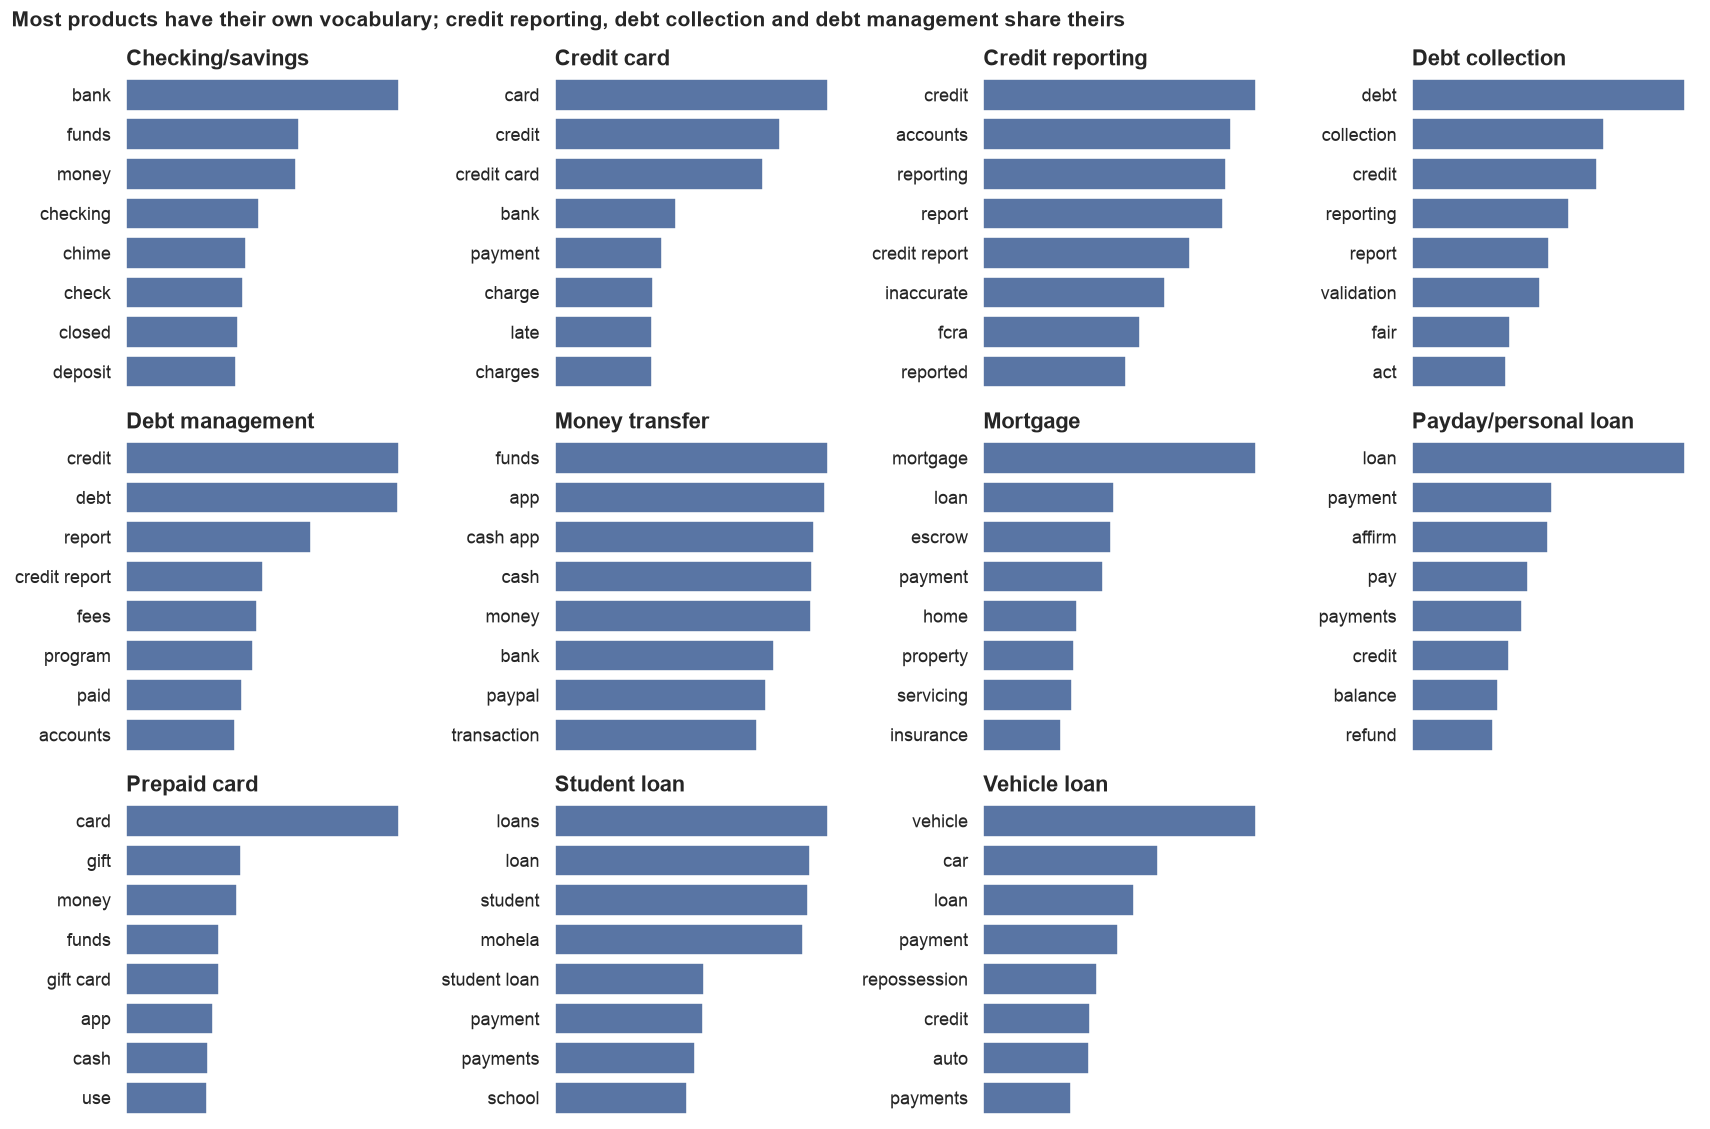

In [18]:
# PURPOSE: Identify distinguishing words with per-product TF-IDF scores.
# Top 8 distinctive terms per product (highest average TF-IDF score)
distinct = distinctive_terms(text_df["clean"], text_df["product_short"], n=8)

# One small bar chart per product, arranged in a 3 x 4 grid
products = sorted(distinct["product"].unique())
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, product in zip(axes.flat, products):
    terms = distinct[distinct["product"] == product]   # this product's 8 terms
    sns.barplot(data=terms, x="score", y="term", color=MAIN, ax=ax)
    ax.set(title=product, xlabel="", ylabel="", xticks=[])   # scores only compare words within a product, so no x-axis
    sns.despine(ax=ax, left=True, bottom=True)
axes.flat[-1].axis("off")    # 11 products in a 12-slot grid: hide the empty one

fig.suptitle("Most products have their own vocabulary; credit reporting, debt collection and debt management share theirs",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

- **Eight products have clear, product-specific vocabulary:** mortgage (*escrow, property, servicing*), student loan (*school, mohela*), vehicle loan (*repossession, auto*), checking/savings (*deposit, check*), prepaid card (*gift card*). These should be easy to classify.
- **Credit reporting, debt collection and debt management share their top words** (*credit*, *report*). Debt management complaints are often about credit repair companies promising to fix a credit report, so their language overlaps with credit reporting. These categories share similar vocabulary, so we will examine whether the classification models confuse them more frequently in Phase 3.
- Company names show up as distinctive terms (*chime, mohela, affirm, paypal*). This confirms the point from 2.2: part of the signal is *who* the complaint is about, not just *what* it is about.

### 2.4 Word clouds: overlapping vs. distinct vocabulary

Word size shows how distinctive a word is for that product (TF-IDF). The three overlapping products sit beside mortgage, which has its own vocabulary.

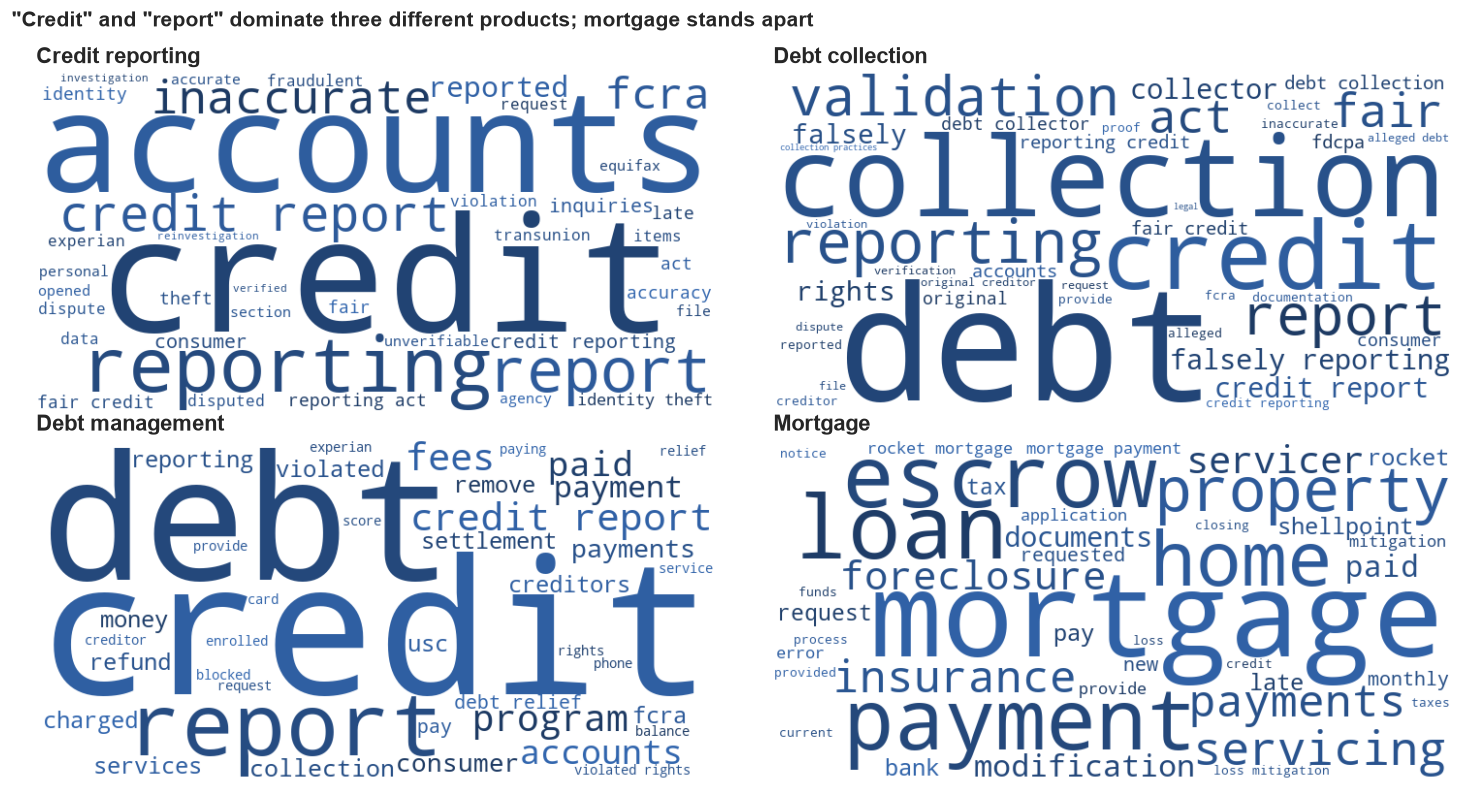

In [19]:
# PURPOSE: Build word clouds to compare vocabulary across selected products.
# Word clouds for the three overlapping products and one distinct product
cloud_products = ["Credit reporting", "Debt collection", "Debt management", "Mortgage"]
cloud_terms = distinctive_terms(text_df["clean"], text_df["product_short"], n=40)   # top 40 TF-IDF terms per product

# Helper: dark blue for the analysis below.
def dark_blue(*args, **kwargs):
    # Colour every word in a readable dark blue (shades vary for texture)
    return f"hsl(215, 55%, {np.random.randint(25, 45)}%)"

# Draw one cloud per product in a 2 x 2 grid; word size = TF-IDF score
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, product in zip(axes.flat, cloud_products):
    weights = cloud_terms[cloud_terms["product"] == product].set_index("term")["score"].to_dict()   # {word: score}
    cloud = WordCloud(width=700, height=350, background_color="white", color_func=dark_blue,
                      prefer_horizontal=1.0, random_state=1).generate_from_frequencies(weights)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(product)
    ax.axis("off")   # hide the axes around the image

fig.suptitle('"Credit" and "report" dominate three different products; mortgage stands apart',
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

The first three clouds are dominated by the same words (*credit, report, reporting, debt*), while the mortgage cloud shares almost none of them. For the routing team this means a complaint that talks about a credit report could belong to any of three teams; the deciding clues are smaller words such as *validation* (debt collection) or *program, fees* (debt management).

### 2.5 Vocabulary Overlap Across Financial Products (Jaccard Similarity)

We use Jaccard similarity to measure how much vocabulary is shared between financial product categories.

Jaccard similarity compares the number of shared words with the total number of unique words across two sets.

A score of 0 indicates no shared words, while a score of 1 indicates identical word sets.

This analysis helps us identify product categories with similar vocabulary and explore which categories might be more difficult to distinguish during predictive modeling.

In [20]:
# PURPOSE: Construct the per-product vocabulary sets for overlap analysis.
# Get the 50 most common meaningful words for each financial product
top_words_by_product = {}

for product, group in text_df.groupby("Product"):

    # Combine the cleaned narratives and remove stopwords
    words = " ".join(group["clean"]).split()
    words = [word for word in words if word not in STOPWORDS]

    # Select the 50 most frequent words for each product
    word_counts = Counter(words)
    top_words_by_product[product] = set(
        word for word, count in word_counts.most_common(50)
    )

# Calculate Jaccard similarity between each pair of products
products = list(top_words_by_product.keys())

# Jaccard overlap is intersection divided by union of the top-term sets.
jaccard_matrix = pd.DataFrame(
    index=products,
    columns=products,
    dtype=float
)

for product_a in products:
    for product_b in products:
        words_a = top_words_by_product[product_a]
        words_b = top_words_by_product[product_b]

        # Count shared words and total unique words
        shared_words = len(words_a.intersection(words_b))
        total_unique_words = len(words_a.union(words_b))

        # Calculate Jaccard similarity
        jaccard_matrix.loc[product_a, product_b] = (
            shared_words / total_unique_words if total_unique_words else 0
        )

# Display the similarity scores
display(jaccard_matrix.round(2))

,Checking or savings account,Credit card,Credit reporting or other personal consumer reports,Debt collection,Debt or credit management,"Money transfer, virtual currency, or money service",Mortgage,"Payday loan, title loan, personal loan, or advance loan",Prepaid card,Student loan,Vehicle loan or lease
Checking or savings account,1.00,0.37,0.16,0.16,0.25,0.54,0.20,0.27,0.47,0.16,0.20
Credit card,0.37,1.00,0.19,0.22,0.39,0.32,0.25,0.45,0.32,0.25,0.35
Credit reporting or other personal consumer reports,0.16,0.19,1.00,0.47,0.27,0.10,0.11,0.20,0.09,0.16,0.23
Debt collection,0.16,0.22,0.47,1.00,0.37,0.14,0.16,0.32,0.12,0.20,0.33
Debt or credit management,0.25,0.39,0.27,0.37,1.00,0.23,0.28,0.45,0.20,0.33,0.39
"Money transfer, virtual currency, or money service",0.54,0.32,0.10,0.14,0.23,1.00,0.19,0.27,0.54,0.18,0.19
Mortgage,0.20,0.25,0.11,0.16,0.28,0.19,1.00,0.32,0.18,0.28,0.35
"Payday loan, title loan, personal loan, or advance loan",0.27,0.45,0.20,0.32,0.45,0.27,0.32,1.00,0.25,0.32,0.54
Prepaid card,0.47,0.32,0.09,0.12,0.20,0.54,0.18,0.25,1.00,0.14,0.16
Student loan,0.16,0.25,0.16,0.20,0.33,0.18,0.28,0.32,0.14,1.00,0.28


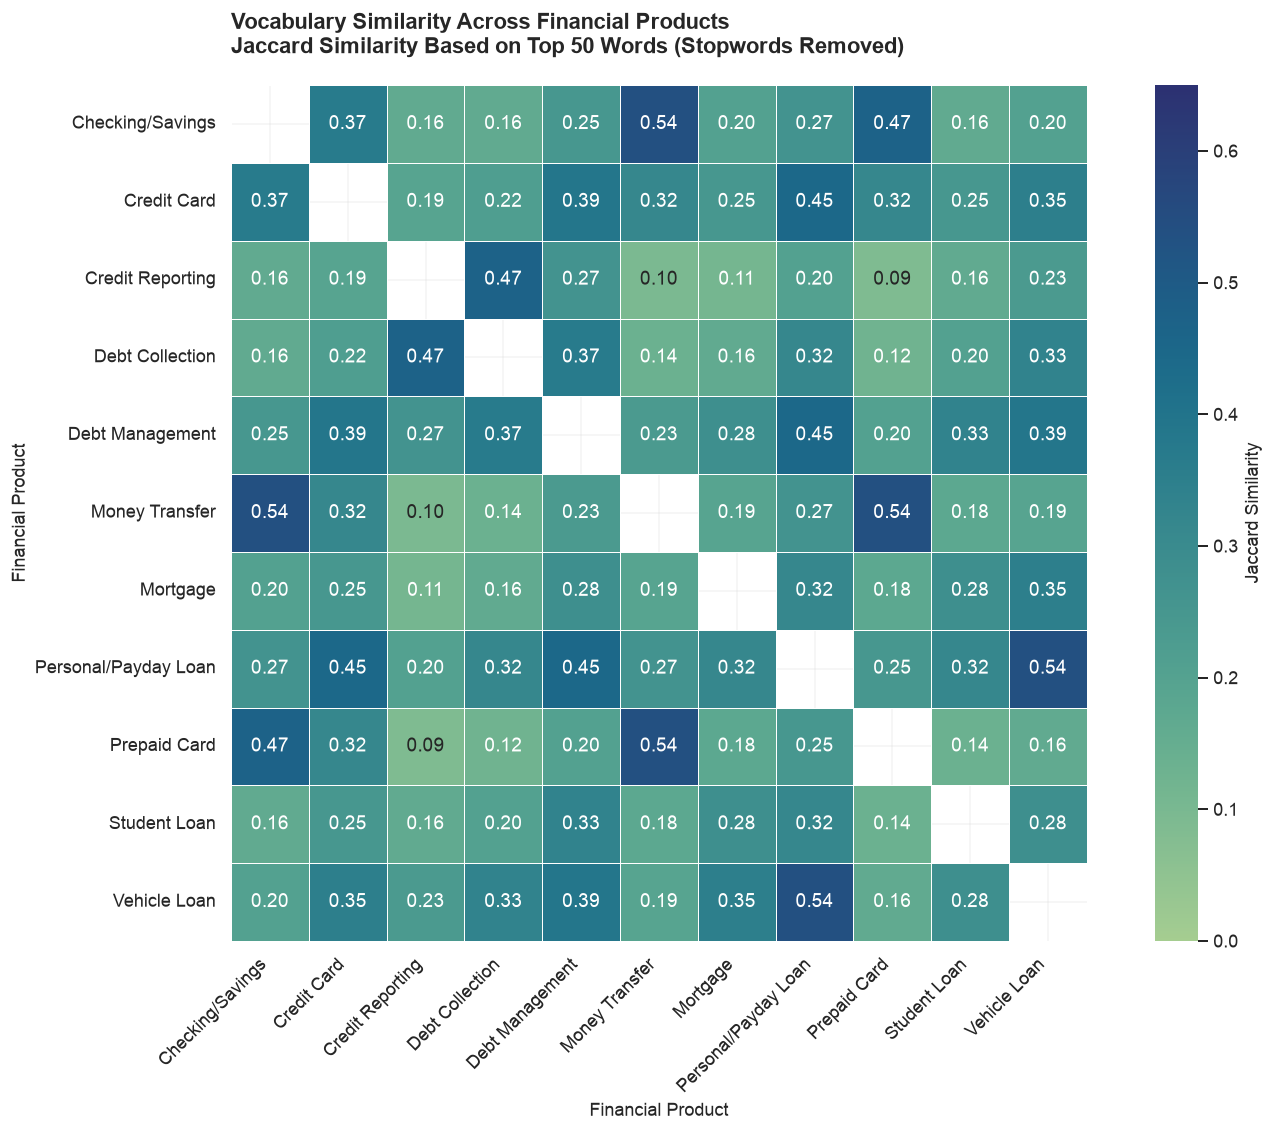

In [21]:
# PURPOSE: Plot the Jaccard similarity matrix with concise product labels.
# Shorten product names to make the heatmap easier to read
short_names = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt Management",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Personal/Payday Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

# Apply shorter labels without changing the similarity scores
plot_matrix = jaccard_matrix.rename(
    index=short_names,
    columns=short_names
)

# Hide self-comparisons along the diagonal
mask = np.eye(len(plot_matrix), dtype=bool)

plt.figure(figsize=(13.5, 10))

sns.heatmap(
    plot_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="crest",
    vmin=0,
    vmax=0.65,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Jaccard Similarity"}
)

plt.title(
    "Vocabulary Similarity Across Financial Products\n"
    "Jaccard Similarity Based on Top 50 Words (Stopwords Removed)",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Financial Product")
plt.ylabel("Financial Product")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Interpretation: vocabulary overlap

Jaccard similarity compares each product category’s **50 most frequent meaningful words**. Larger values indicate more shared vocabulary, not necessarily higher classification error. The observed **Checking/Savings–Money Transfer** overlap is **0.54**, and **Credit Reporting–Debt Collection** is **0.47**; **Credit Reporting–Prepaid Card** is **0.09**. Other pairs may also have high overlap: consult the heatmap rather than assuming all pairs tied at 0.54. We assess whether vocabulary overlap translates into errors using the held-out confusion matrix in Section 5.

### 2.6 Do complaints name their own product?

If most complaints simply say "my mortgage" or "my student loan", classification is easy but partly trivial. The chart shows, for complaints of each product (rows), the share that mention the key words of each product (columns). Numbers on the outlined diagonal mean complaints name their own product; strong numbers off the diagonal mean they mention another product's words.

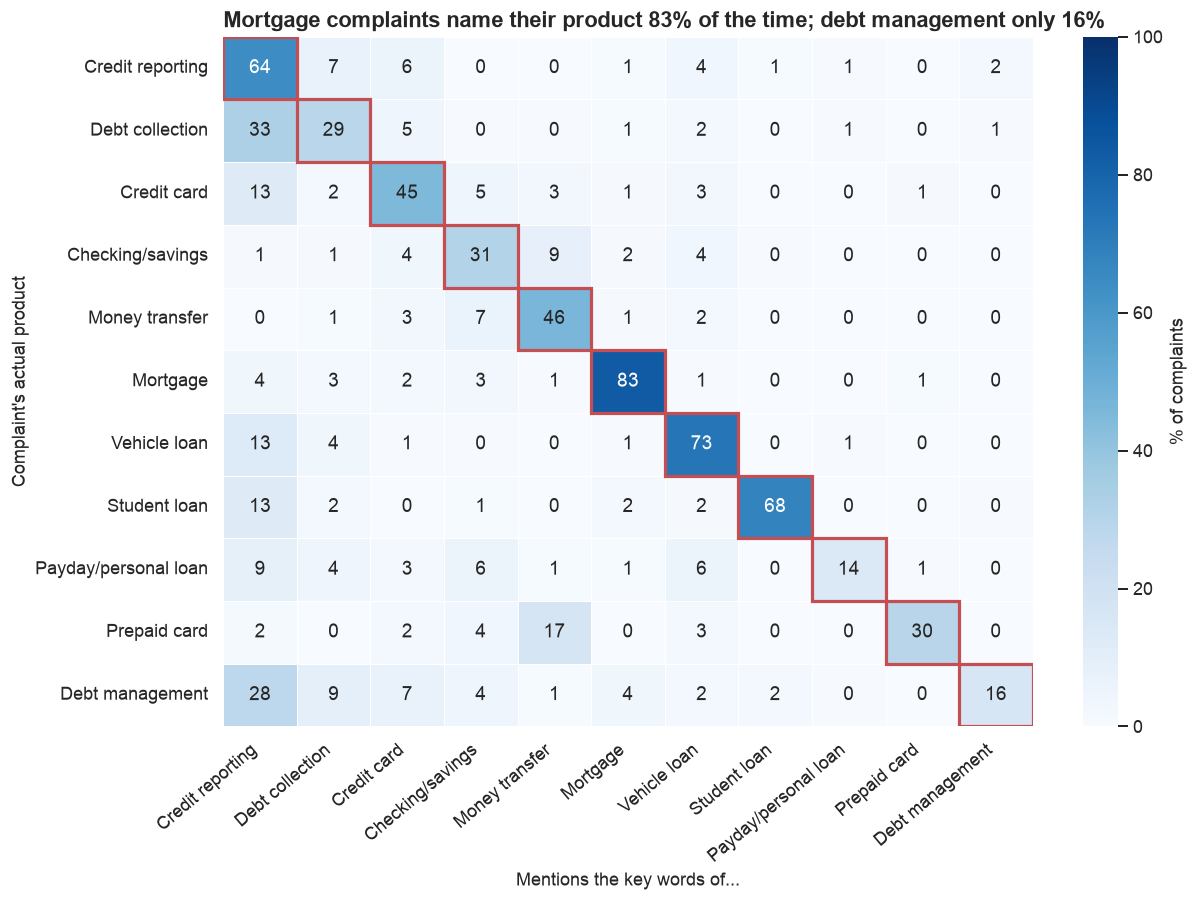

In [22]:
# PURPOSE: Measure product-name mentions in complaint narratives.
# % of complaints in each product (rows) that mention each product's key words (columns)
mentions = product_word_matrix(text_df)

# Heatmap: rows = actual product, columns = product whose key words are mentioned, cell = % of complaints
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(mentions, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "% of complaints"}, ax=ax)
ax.set(xlabel="Mentions the key words of...", ylabel="Complaint's actual product",
       title="Mortgage complaints name their product 83% of the time; debt management only 16%")

# Outline the diagonal: complaints mentioning their own product's words
for i in range(len(mentions)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor=ACCENT, linewidth=2))
plt.xticks(rotation=40, ha="right")   # tilt column names so they do not overlap
plt.tight_layout()
plt.show()

- **Some products almost always name themselves:** mortgage (83%), vehicle loan (73%), student loan (68%) and credit reporting (64%). For these, a model can score well just by spotting the product word, which is why Phase 3 will **re-test the model with these words masked** to see how much accuracy depends on them.
- **Others rarely do:** only 14% of payday/personal loan and 16% of debt management complaints use their own product's words. These classes depend on indirect clues and will likely be harder.
- **The key off-diagonal finding:** 33% of debt collection complaints and 28% of debt management complaints use credit-reporting words, as much as or more than their own. This matches 2.3 and 2.4: credit reporting, debt collection and debt management are the classes we expect the model to confuse, and the cases where the routing team would most benefit from a second look.

### 2.7 Sentiment Analysis Using VADER

We use VADER sentiment analysis to examine the emotional tone of consumer complaint narratives. VADER assigns sentiment scores based on the words and expressions in a text.

This analysis will help us understand the overall sentiment of complaints and compare sentiment across financial product categories.

In [23]:
# PURPOSE: Score raw narratives with baseline VADER sentiment.
# Baseline VADER score for every complaint
text_df["sentiment_raw"] = sentiment_scores(text_df[TEXT_COL])            # compound score from -1 to +1
text_df["label_raw"] = sentiment_label(text_df["sentiment_raw"])          # Negative < -0.05 <= Neutral <= 0.05 < Positive

# Share of complaints in each sentiment label
print("Share of complaints by sentiment label (baseline VADER):")
print((text_df["label_raw"].value_counts(normalize=True) * 100).round(1).to_string())

Share of complaints by sentiment label (baseline VADER):
label_raw
Negative    60.1
Positive    36.0
Neutral      3.9


- VADER calls about **36% of complaints positive**, even though every narrative here is a complaint. To find out why, we add up which positive dictionary words contribute most across all complaints.

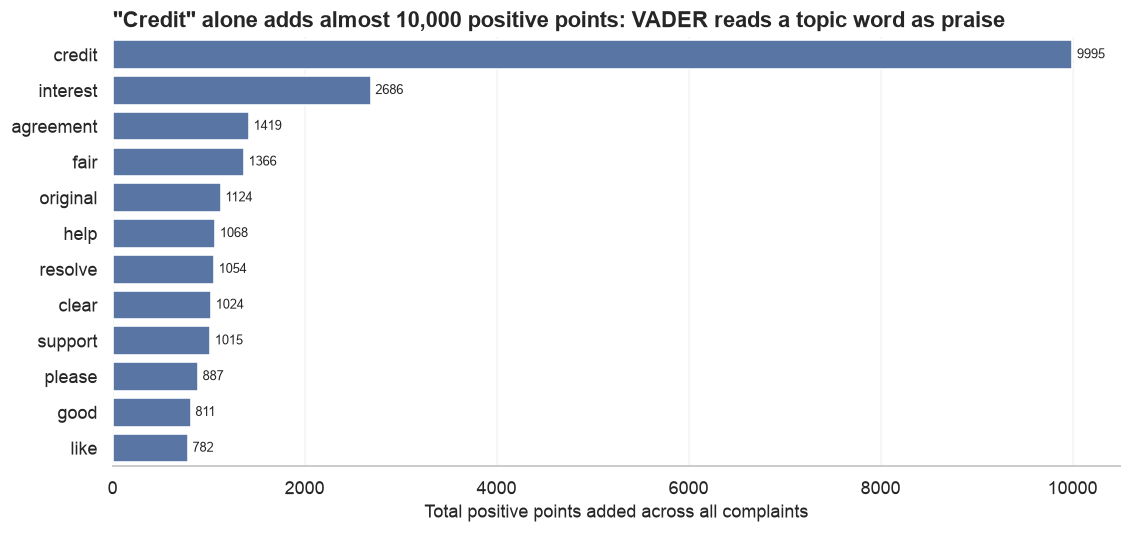

In [24]:
# PURPOSE: Inspect positive-scoring words that may be misleading in finance.
# Positive dictionary words that add the most to VADER scores
contributions = positive_word_contributions(text_df["clean"], n=12)   # top 12 words by total positive score added

# Horizontal bar chart of those words
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=contributions, x="positive_points", y="word", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=8)
ax.set(xlabel="Total positive points added across all complaints", ylabel="",
       title='"Credit" alone adds almost 10,000 positive points: VADER reads a topic word as praise')
sns.despine(left=True)
plt.tight_layout()
plt.show()

- VADER was built for social media, where *credit* means praise ("give credit") and *interest* means curiosity. In financial complaints these are **topic words**: *credit report*, *interest rate*, the **Fair** Credit Reporting Act, a loan **agreement**, even **Wells** Fargo. They inflate scores, most of all for credit-related products.

**Domain-adjusted sentiment analysis:** We make selected financial terms neutral in VADER's dictionary (`FINANCE_WORDS` in `src/text_analysis.py`) and calculate sentiment scores again. This is an experimental adjustment to reduce the influence of financial terminology, not a guaranteed improvement in sentiment accuracy.


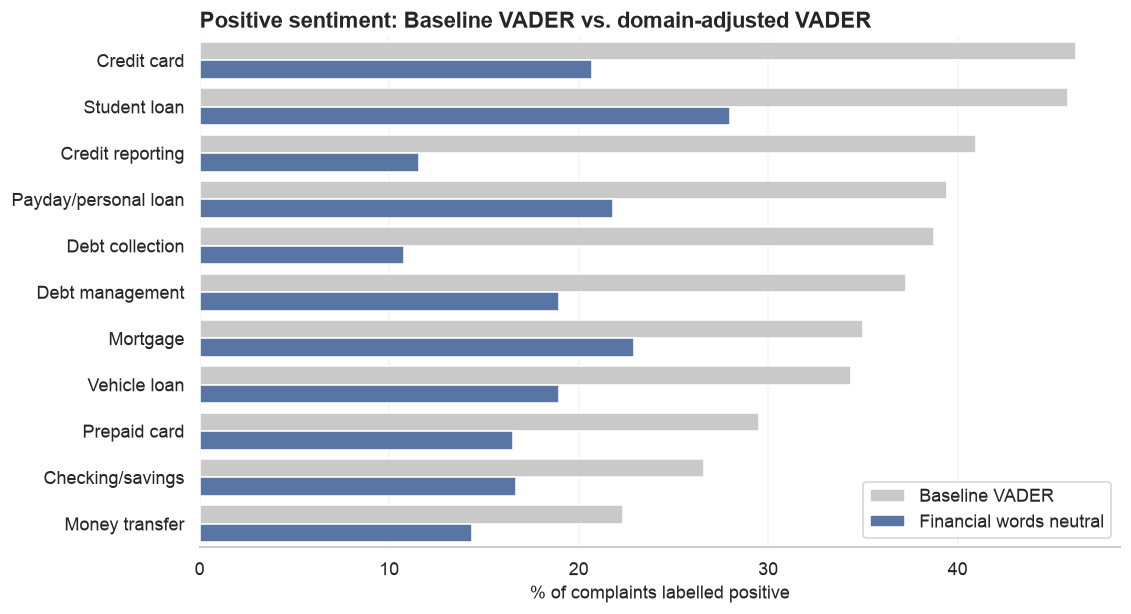

Overall share labelled positive: baseline 36%, domain-adjusted 18%


In [25]:
# PURPOSE: Neutralize selected financial terms and recompute sentiment labels.
# Re-score with financial topic words made neutral
# Finance-aware lexicon adjustments are exploratory, not a validated sentiment model.
text_df["sentiment"] = sentiment_scores(text_df[TEXT_COL], neutral_words=FINANCE_WORDS)   # FINANCE_WORDS scored as 0
text_df["label"] = sentiment_label(text_df["sentiment"])

# Compare positive sentiment percentages before and after domain adjustment
positive_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
    "Financial words neutral": text_df["label"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
}).sort_values("Baseline VADER", ascending=False)

# Reshape to long format (one row per product and version) so seaborn can draw paired bars
plot_data = positive_share.reset_index().melt(id_vars="product_short", var_name="version",
                                              value_name="pct_positive")
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="pct_positive", y="product_short", hue="version",
            palette=["#c9c9c9", MAIN], ax=ax)
ax.set(xlabel="% of complaints labelled positive", ylabel="",
       title="Positive sentiment: Baseline VADER vs. domain-adjusted VADER")
ax.legend(title="", loc="lower right")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Compare the overall share of positive sentiment before and after domain adjustment
print("Overall share labelled positive:",
      f"baseline {text_df['label_raw'].eq('Positive').mean():.0%},",
      f"domain-adjusted {text_df['label'].eq('Positive').mean():.0%}")

- After making selected financial terms neutral, VADER classified approximately **77% of complaints as negative**, compared with the baseline results.
- The percentage classified as positive decreased, especially for credit reporting, debt collection, and credit card complaints.
- About **18% of complaints still received positive sentiment labels**. Words such as *help*, *resolve*, *support*, and *please* may contribute to these scores even when consumers are describing problems.
- **Takeaway:** Domain-specific terminology can influence sentiment scores. However, this adjustment is experimental, and we would need manually labeled sentiment data to determine whether it improves accuracy.


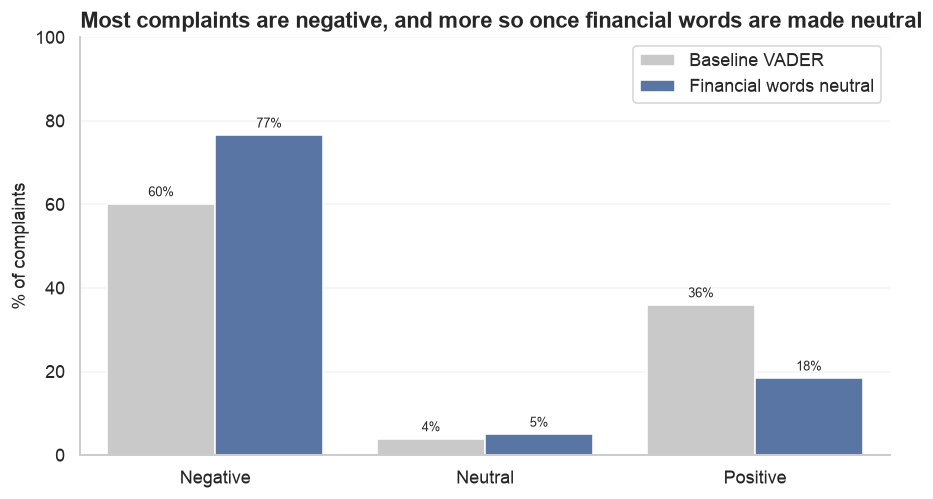

          Baseline VADER  Financial words neutral
Negative            60.1                     76.6
Neutral              3.9                      5.0
Positive            36.0                     18.4


In [26]:
# PURPOSE: Compare baseline and finance-adjusted sentiment distributions.
# Share of complaints by sentiment label: baseline VADER vs. financial words neutral
order = ["Negative", "Neutral", "Positive"]   # fixed order for the x-axis
label_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].value_counts(normalize=True) * 100,
    "Financial words neutral": text_df["label"].value_counts(normalize=True) * 100,
}).reindex(order)

# Reshape to long format (one row per label and version) for paired bars
plot_data = label_share.reset_index(names="sentiment").melt(id_vars="sentiment", var_name="version",
                                                            value_name="pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_data, x="sentiment", y="pct", hue="version", order=order,
            palette=["#c9c9c9", MAIN], ax=ax)
for container in ax.containers:   # write the % above every bar
    ax.bar_label(container, fmt="%.0f%%", padding=3, fontsize=8)
ax.set(xlabel="", ylabel="% of complaints", ylim=(0, 100),
       title="Most complaints are negative, and more so once financial words are made neutral")
ax.legend(title="", loc="upper right")
sns.despine()
plt.tight_layout()
plt.show()

print(label_share.round(1).to_string())

- With baseline VADER, **60% of complaints are negative, 36% positive and 4% neutral**. Since every narrative is a complaint, a positive share this high is a warning sign.
- After financial topic words (*credit*, *interest*, *fair*, *agreement*) are made neutral, **77% of complaints are negative and 18% positive**. Almost all of the change moves from positive to negative; the neutral share stays small (4% to 5%).

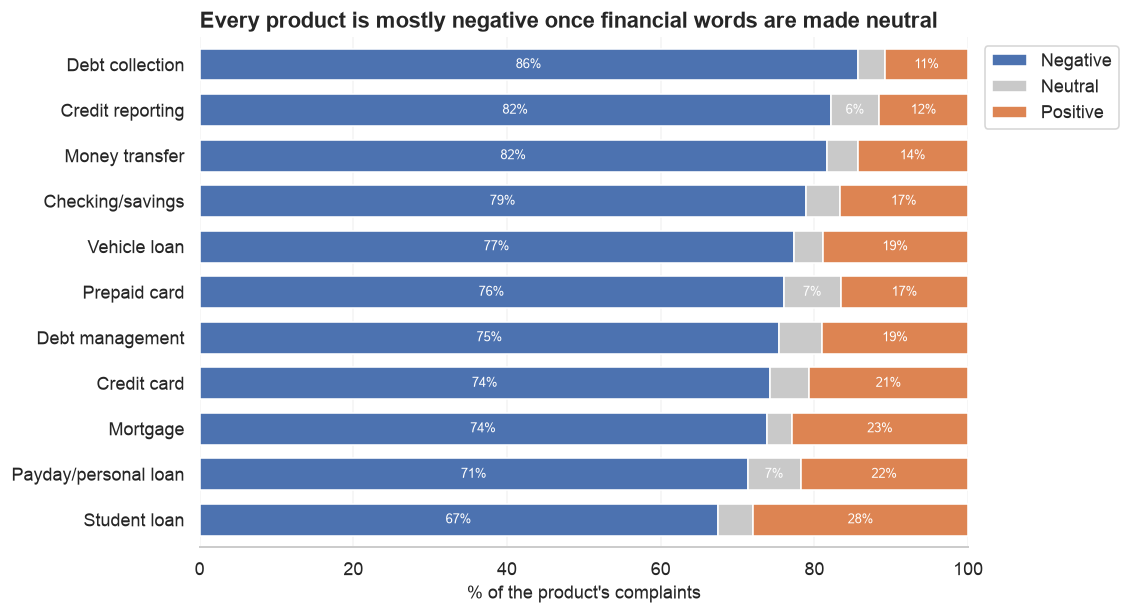

label                 Negative  Neutral  Positive
product_short                                    
Debt collection           85.6      3.6      10.8
Credit reporting          82.2      6.3      11.6
Money transfer            81.6      4.0      14.4
Checking/savings          78.9      4.4      16.7
Vehicle loan              77.3      3.7      18.9
Prepaid card              76.0      7.5      16.5
Debt management           75.4      5.6      19.0
Credit card               74.2      5.1      20.7
Mortgage                  73.8      3.3      22.9
Payday/personal loan      71.4      6.8      21.8
Student loan              67.4      4.6      28.0


In [27]:
# PURPOSE: Visualize sentiment mix by product category.
# Negative / neutral / positive mix for each product (financial words neutral)
# % of each product's complaints in each label (each row adds up to 100)
sentiment_by_product = (pd.crosstab(text_df["product_short"], text_df["label"], normalize="index") * 100)
sentiment_by_product = sentiment_by_product[["Negative", "Neutral", "Positive"]].sort_values("Negative")

# One stacked bar per product: negative + neutral + positive = 100%
ax = sentiment_by_product.plot(kind="barh", stacked=True, figsize=(10, 5.5), width=0.7,
                               color=["#4c72b0", "#c9c9c9", "#dd8452"])
# Label each segment with its %, skipping segments under 6% that are too narrow to read
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 6 else "" for v in container.datavalues],
                 label_type="center", fontsize=8, color="white")
ax.set(xlim=(0, 100), xlabel="% of the product's complaints", ylabel="",
       title="Every product is mostly negative once financial words are made neutral")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(sentiment_by_product.round(1).sort_values("Negative", ascending=False).to_string())

- **Every product is mostly negative** once financial words are made neutral. Debt collection has the highest negative share (86%) and student loan the lowest (67%, with the highest positive share at 28%).
- Debt collection and credit reporting have some of the highest negative sentiment percentages after the domain adjustment. Their positive sentiment percentages decreased substantially, suggesting that financial terminology influenced the original VADER scores. However, we cannot confirm that the original positive labels were incorrect without manually reviewing and labeling the complaints.

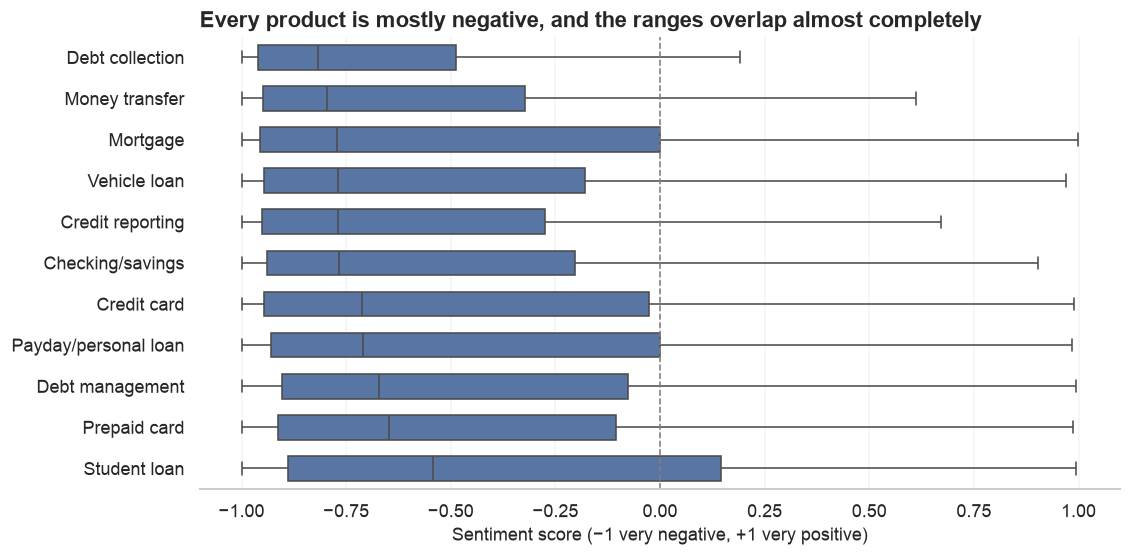

                              median  count
Company response to consumer               
Closed with explanation        -0.74   3971
Other                          -0.36    201
Relief given                   -0.75    723


In [28]:
# PURPOSE: Compare adjusted sentiment score distributions across products.
# Does sentiment differ by product? (adjusted scores)
# Products ordered from most negative to least negative median score
order_by_sentiment = text_df.groupby("product_short")["sentiment"].median().sort_values().index

# Box = middle half of scores, line = median, whiskers = typical range (outliers hidden)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=text_df, x="sentiment", y="product_short", order=order_by_sentiment,
            color=MAIN, showfliers=False, width=0.6, ax=ax)
ax.axvline(0, color="grey", linewidth=1, linestyle="--")   # neutral line
ax.set(xlabel="Sentiment score (−1 very negative, +1 very positive)", ylabel="",
       title="Every product is mostly negative, and the ranges overlap almost completely")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Does sentiment differ by how the company responded?
# Group company responses into three outcomes, then compare median sentiment and counts
outcome = text_df["Company response to consumer"].map(
    lambda r: "Relief given" if "relief" in r else ("Closed with explanation" if "explanation" in r else "Other"))
print(text_df.groupby(outcome)["sentiment"].agg(["median", "count"]).round(2))

**Interpretation.** Adjusted VADER scores are generally negative across categories, with substantial overlap in their distributions. This descriptive evidence suggests that **sentiment alone is unlikely to be a strong product-category discriminator**; we do not include it in the classifier features. We have **not** validated VADER as a measure of complaint severity, urgency, or consumer outcomes. Claims that sentiment predicts relief or that a language model would reliably identify urgency would require a separate labeled evaluation.

### 2.8 Summary: what Phase 2 means for Phase 3

| Finding | Evidence | Phase 3 action |
|---|---|---|
| Balanced sample (454–455 per product); real complaints are 91% credit reporting | 1.3 | Report accuracy and macro F1; note that a balanced model over-predicts small products on real traffic |
| 105 exact copies of 44 template letters | 1.6 | Remove copies before the train/test split (4,895 narratives) |
| Most products have their own vocabulary | 2.3, 2.4 | TF-IDF features with logistic regression as the baseline |
| Credit reporting, debt collection and debt management share vocabulary | 2.3–2.5 | Per-class precision and recall, and a confusion matrix |
| Many complaints name their own product (mortgage 83%) | 2.6 | Re-train with product words masked and compare macro F1 |
| Company names are among the most common and distinctive terms | 2.2, 2.3 | Inspect top features; test a version with company names removed |
| Sentiment is mostly negative for every product and overlaps across products | 2.7 | Do not use sentiment as a classification feature |

## 3. Predictive modeling

**Goal.** Predict the **Product** (11 categories, our target **Y**) from the **Consumer complaint narrative** (predictor **X**). The business application is routing incoming messages—such as emails, chats, and call transcripts—to the appropriate financial-product team. The CFPB sample provides labeled examples because each narrative has a consumer-selected product category. This is a **proxy routing task**: the notebook does not test a live routing system.

### How we measure success

**Accuracy** is the percentage of held-out complaints assigned to the correct product. Because all 11 product teams matter, we also report **macro F1**, which gives each category equal weight regardless of how many complaints it contains. For a single product team (for example, Mortgage), the confusion-matrix terms mean:

| Outcome | What it means for routing |
|---|---|
| **True positive (TP)** | A mortgage complaint is correctly routed to Mortgage. |
| **False positive (FP)** | A complaint about another product is incorrectly sent to Mortgage, causing extra work and potential delay. |
| **False negative (FN)** | A mortgage complaint is incorrectly sent elsewhere; Mortgage may never see it promptly. |
| **True negative (TN)** | A non-mortgage complaint is correctly kept out of Mortgage's queue. |

**Precision = TP / (TP + FP)** measures how much of a team's assigned work belongs there; **recall = TP / (TP + FN)** measures how much of the team's actual work reaches it; **specificity = TN / (TN + FP)** measures how reliably other products are excluded. **F1** is the harmonic mean of precision and recall. The reported **macro** metrics average across all 11 products. Where a denominator is zero, the evaluation uses a zero score rather than raising an error.

### Approaches included in our unified comparison

| # | Approach | Why it is included | Training / API requirements |
|---|---|---|---|
| 0 | Majority-class baseline | Establishes the minimum useful reference point. | Local; learns only the most frequent training label. |
| 1 | TF-IDF + Multinomial Naïve Bayes | Fast, interpretable probabilistic text baseline. | Local supervised training. |
| 2 | TF-IDF + Logistic Regression | Strong linear text classifier; provides class probabilities. | Local supervised training. |
| 3 | TF-IDF + Linear SVM | Strong linear classifier for sparse text features. | Local supervised training; raw margins are **not probabilities**. |
| 4 | spaCy word-vector similarity | Tests whether static embeddings can match a complaint to a product description. | Local similarity; cached Claude descriptions. |
| 5 | MiniLM sentence-embedding similarity | Tests semantic sentence representations with **label-only** and **complaint-informed** descriptions separately. | Local similarity; cached Claude descriptions. |
| 6 | Claude zero-shot classification | Tests whether an LLM can classify a complaint directly without supervised training. | **Cached** API predictions only; no new calls here. |

### How methodological choices were made

| Decision | Actual implementation and rationale |
|---|---|
| **Sample** | 5,000 original records; 4,895 unique narratives after exact-duplicate removal. The source sample is approximately balanced across products, **not representative of live complaint volumes**. |
| **Holdout** | One stratified **70/30 split** with random seed **42**, yielding **3,426 training** and **1,469 test** complaints. The same held-out complaint IDs are used for every scored method. |
| **Supervised validation** | **Five-fold stratified cross-validation**, shuffled with seed 42, on the training split only. Each TF-IDF vectorizer is fitted within its training fold. |
| **TF-IDF settings** | **Deliberately specified, not scikit-learn defaults:** unigrams and bigrams; English stopwords; `min_df=3`, `max_df=0.95`, `sublinear_tf=True`. These settings are shared across Naïve Bayes, Logistic Regression, and Linear SVM. |
| **Classifier settings** | Naïve Bayes `alpha=1.0`; Logistic Regression `max_iter=2000`; Linear SVM with seed 42. There is **no exhaustive hyperparameter search** in this unified notebook. |
| **Embedding descriptions** | Rebecca's cached descriptions use category labels only; Ketty's cached descriptions were informed by training complaints. These are **different reference designs**, not a controlled comparison of embedding algorithms alone. |
| **Complaint-informed description size** | For spaCy and MiniLM, `k ∈ {5, 10, 20}` is selected using **training-only accuracy**. The exact complaint IDs used to create the cached descriptions are not available here, so overlap with the selection data cannot be ruled out. The resulting training score is a **heuristic, not an unbiased validation estimate**. |
| **Final supervised model** | Choose the **highest training cross-validation macro F1**, before examining the held-out test results. This selects **Linear SVM** (CV macro F1 ≈ **0.719**). We do **not** apply an unimplemented one-standard-error Logistic Regression preference rule. |
| **Masking robustness** | Retrain and test the selected classifier after masking a **documented, limited list of 15 product-related expressions**. This is **not** every CFPB product/sub-product word. |
| **Subgroup analysis** | Descriptive accuracy by available **Submitted via** and **State** groups with at least 30 test observations; **not** a comprehensive demographic fairness audit. |
| **Manual review** | The notebook reports quantitative errors and examples; it does **not** claim to have completed a separately documented 30-case manual audit. |

**Evaluation boundary.** The test set is reserved for final performance reporting. Cached Claude outputs are joined by **Complaint ID**; missing or invalid predictions count as incorrect. Comparing supervised models with zero-shot Claude is informative, but not a controlled comparison of model development effort, external data, or operating cost.


In [29]:
# PURPOSE: Create one stratified holdout split and a shared evaluation registry.
SEED = 42
RESULTS_DIR = PROJECT_ROOT / "outputs" / "unified_analysis"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Split the ROWS, not different text Series; this guarantees aligned complaint IDs.
# Stratify by product so the holdout retains every product category.
train_df, test_df = train_test_split(text_df, test_size=0.30, stratify=text_df["Product"], random_state=SEED)
train_df, test_df = train_df.copy(), test_df.copy()
X_train, X_test = train_df["clean"].fillna(""), test_df["clean"].fillna("")
y_train, y_test = train_df["Product"], test_df["Product"]
labels = sorted(text_df["Product"].unique())
assert set(train_df.index).isdisjoint(set(test_df.index)), "Train/test row overlap"
assert len(train_df) + len(test_df) == len(text_df)
print(f"Training: {len(train_df):,}; test: {len(test_df):,}; classes: {len(labels)}")
print("Complaint IDs available:", "Complaint ID" in text_df.columns)

# Shared registry: each row represents predictions for the SAME held-out complaints.
predictions = {}
metrics_rows = []
# Helper: record model for the analysis below.
# Register predictions and all metrics against the same test labels.
def record_model(name, y_pred, family, notes=""):
    y_pred = np.asarray(y_pred, dtype=object)
    if len(y_pred) != len(y_test):
        raise ValueError(f"{name}: prediction length does not match held-out test")
    predictions[name] = y_pred
    metrics_rows.append({"Model": name, "Family": family,
                         "Accuracy": accuracy_score(y_test, y_pred),
                         "Macro F1": f1_score(y_test, y_pred, labels=labels, average="macro", zero_division=0),
                         "Macro Precision": precision_score(y_test, y_pred, labels=labels, average="macro", zero_division=0),
                         "Macro Recall": recall_score(y_test, y_pred, labels=labels, average="macro", zero_division=0),
                         "Notes": notes})

Training: 3,426; test: 1,469; classes: 11
Complaint IDs available: True


### 3.1 Majority-class baseline
A no-skill reference: always predict the most frequent category in the **training** data. This prevents us from overinterpreting accuracy on a deliberately balanced sample.

In [30]:
# PURPOSE: Fit a majority-class classifier as the no-skill reference.
# Predict the most frequent training label for every test complaint.
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
record_model("Majority class", baseline.predict(X_test), "Baseline")

### 3.2 TF-IDF supervised models and training-only cross-validation

We compare Multinomial Naïve Bayes, Logistic Regression, and Linear SVM under the **same specified TF-IDF feature configuration**: unigrams and bigrams, English stopwords, `min_df=3`, `max_df=0.95`, and sublinear term frequency. These are **not all library defaults**. A full `Pipeline` is evaluated within each of five stratified training folds, so vocabulary and inverse-document-frequency weights are learned **without seeing the validation fold**.

The selection rule is **highest mean training CV macro F1**. On the uploaded run, Linear SVM ranked first (approximately **0.719**, versus **0.712** for Logistic Regression and **0.669** for Naïve Bayes). The held-out test set is used **after** selection to estimate performance, not to choose the winning supervised model.


In [31]:
# PURPOSE: Cross-validate TF-IDF pipelines on training folds and fit each final model.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
TFIDF_SETTINGS = dict(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.95, sublinear_tf=True)
model_specs = {"Naïve Bayes": MultinomialNB(alpha=1.0),
               "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
               "Linear SVM": LinearSVC(random_state=SEED)}
fitted_models, cv_rows = {}, []
# Fit TF-IDF within each CV fold to prevent validation vocabulary leakage.
for name, estimator in model_specs.items():
    pipeline = Pipeline([("tfidf", TfidfVectorizer(**TFIDF_SETTINGS)), ("model", estimator)])
    scores = cross_validate(pipeline, X_train, y_train, cv=CV,
                            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"}, n_jobs=-1)
    cv_rows.append({"Model": name, "CV Accuracy": scores["test_accuracy"].mean(),
                    "CV Macro F1": scores["test_macro_f1"].mean(),
                    "CV F1 SD": scores["test_macro_f1"].std()})
    fitted_models[name] = pipeline.fit(X_train, y_train)
    record_model(name, fitted_models[name].predict(X_test), "TF-IDF supervised")
cv_table = pd.DataFrame(cv_rows).sort_values("CV Macro F1", ascending=False)
display(cv_table.round(3))
cv_table.to_csv(RESULTS_DIR / "training_cross_validation.csv", index=False)

# Select the supervised deployment candidate by TRAINING CV, not test-set ranking.
# Select by cross-validated training macro F1; do not use held-out scores.
selected_name = cv_table.iloc[0]["Model"]
selected_model = fitted_models[selected_name]
print("Selected by training CV macro F1:", selected_name)

,Model,CV Accuracy,CV Macro F1,CV F1 SD
2,Linear SVM,0.722,0.719,0.015
1,Logistic Regression,0.712,0.712,0.015
0,Naïve Bayes,0.676,0.669,0.023


Selected by training CV macro F1: Linear SVM


### 3.3 Cached Claude descriptions — two distinct experimental designs
**Rebecca:** Claude wrote category descriptions from **product names only** (no complaints sent). **Ketty:** Claude wrote descriptions using sampled **training complaints** (5/10/20 per category). These are not equivalent reference texts. For each embedding model, we report which descriptions were used and do not attribute differences solely to the encoder.

No Claude calls are made here. If a saved file is missing or its schema is unexpected, that experiment is skipped with an explanation.

In [32]:
# PURPOSE: Read saved Claude descriptions and prediction caches; never call the API.
# Load only existing outputs; never invoke Anthropic in this submission notebook.
REBECCA_DESC = PROJECT_ROOT / "outputs" / "rebecca_modelling" / "claude_label_only_descriptions.json"
KETTY_DESC = DATA_DIR / "claude_product_descriptions.csv"
ZS_CACHE = DATA_DIR / "claude_zero_shot_haiku.csv"
SPEND_CACHE = DATA_DIR / "claude_spend_log.csv"

label_descriptions = None
# Validate the label-only cache before including it in the comparison.
if REBECCA_DESC.exists():
    raw = json.loads(REBECCA_DESC.read_text(encoding="utf-8"))
    if isinstance(raw, dict) and set(labels).issubset(raw):
        label_descriptions = pd.DataFrame({"Product": labels, "description": [raw[x] for x in labels]})
        print("Loaded Rebecca label-only descriptions:", len(label_descriptions))
    else:
        print("Rebecca description cache found but labels/schema do not match; skipped.")
else:
    print("Rebecca description cache missing; label-only embedding experiment unavailable.")

ketty_descriptions = None
# Read the complaint-informed reference descriptions without regenerating them.
if KETTY_DESC.exists():
    temp = pd.read_csv(KETTY_DESC)
    if {"Product", "description", "k"}.issubset(temp.columns):
        ketty_descriptions = temp
        print("Loaded Ketty complaint-informed descriptions:", len(temp))
    else:
        print("Ketty description cache has unexpected columns:", temp.columns.tolist())
else:
    print("Ketty description cache missing; complaint-informed embedding experiments unavailable.")

# Helper: aligned descriptions for the analysis below.
def aligned_descriptions(table):
    # Only score if exactly one usable description exists for every target class.
    if table is None or table["Product"].duplicated().any() or set(table["Product"]) != set(labels):
        return None
    return table.set_index("Product").loc[labels, "description"].fillna("").astype(str).tolist()

Loaded Rebecca label-only descriptions: 11
Loaded Ketty complaint-informed descriptions: 33


### 3.4 spaCy word-vector similarity

The `en_core_web_md` model represents a text by aggregating static word vectors. We compute cosine similarity between each complaint and 11 **complaint-informed** product descriptions generated earlier in Ketty's workflow. The nearest description supplies the predicted product. No classifier is fitted on the product labels in this step.

The number of description-source examples per product, **k = 5, 10, or 20**, is chosen from **training-only** prediction accuracy. **Caution:** the original IDs used to draft those cached descriptions were not retained in this notebook, so the selection scores may be optimistic if some source complaints also appear in the training comparison. The held-out test set is not used to choose k.


In [33]:
# PURPOSE: Evaluate spaCy similarity using cached complaint-informed descriptions.
RUN_SPACY = True
spacy_nlp = None
if RUN_SPACY and ketty_descriptions is not None:
    try:
        spacy_nlp = spacy.load("en_core_web_md", exclude=["tagger", "parser", "ner", "attribute_ruler", "lemmatizer", "senter"])
    except (ImportError, OSError) as exc:
        print("spaCy model unavailable; install spaCy and en_core_web_md to enable:", exc)

# Helper: spacy encode for the analysis below.
def spacy_encode(texts):
    return np.vstack([doc.vector for doc in spacy_nlp.pipe([str(x) for x in texts], batch_size=64)])

# Helper: similarity predictions for the analysis below.
# Normalize vectors and choose the highest cosine-similarity product label.
def similarity_predictions(text_vectors, reference_vectors, categories):
    scores = normalize(text_vectors) @ normalize(reference_vectors).T
    return np.asarray(categories, dtype=object)[scores.argmax(axis=1)], scores

# Reference descriptions were created in an earlier notebook. The exact IDs used in
# their generation are not recorded here, so we cannot reconstruct a genuinely
# description-independent validation subset from a fresh random sample.
# Use training data only to choose k, and disclose potential reference overlap.
# A future experiment should persist source complaint IDs and exclude them here.
K_OPTIONS = [5, 10, 20]
selection_mask = np.ones(len(train_df), dtype=bool)

# Helper: pick reference by training accuracy for the analysis below.
# Choose k on training data only; cached source-example overlap remains unverified.
def pick_reference_by_training_accuracy(encoder, train_vectors, descriptions):
    # Training-only heuristic; source-example overlap may make k scores optimistic.
    scores = []
    for k in K_OPTIONS:
        table = descriptions.loc[descriptions["k"] == k]
        texts = aligned_descriptions(table)
        if texts is None:
            continue
        ref = encoder(texts)
        pred, _ = similarity_predictions(train_vectors[selection_mask], ref, labels)
        scores.append((k, accuracy_score(y_train.iloc[np.flatnonzero(selection_mask)], pred)))
    if not scores:
        return None
    return sorted(scores, key=lambda x: (-x[1], x[0]))[0][0]

if spacy_nlp is not None:
    spacy_train = spacy_encode(X_train)
    spacy_test = spacy_encode(X_test)
    best_k_spacy = pick_reference_by_training_accuracy(spacy_encode, spacy_train, ketty_descriptions)
    if best_k_spacy is not None:
        refs = aligned_descriptions(ketty_descriptions.query("k == @best_k_spacy"))
        pred, _ = similarity_predictions(spacy_test, spacy_encode(refs), labels)
        record_model("spaCy + complaint-informed descriptions", pred, "Embedding similarity", f"k={best_k_spacy}")
        print("spaCy selected k:", best_k_spacy)

spaCy selected k: 20


### 3.5 MiniLM sentence-transformer similarity

`all-MiniLM-L6-v2` creates sentence embeddings for the **original narratives**, preserving more context than a static average of word vectors. Cosine similarity assigns each complaint to the nearest product description. We report **two separate experiments**:

1. **Label-only descriptions (Rebecca):** Claude received category names, **not complaint narratives**.
2. **Complaint-informed descriptions (Ketty):** Claude-generated descriptions incorporate training complaint examples; **k = 5, 10, or 20** is chosen using the training-only heuristic described above.

Both use MiniLM, but they differ in reference text and its provenance. Consequently, their performance gap does **not** isolate the causal effect of complaint-informed descriptions.


In [34]:
# PURPOSE: Evaluate MiniLM similarity with two different reference-description sources.
RUN_MINILM = True
sbert = None
if RUN_MINILM and (label_descriptions is not None or ketty_descriptions is not None):
    try:
        sbert = SentenceTransformer("all-MiniLM-L6-v2")
    except (ImportError, OSError, RuntimeError) as exc:
        print("MiniLM unavailable; skipping embedding comparisons:", exc)

# Helper: minilm encode for the analysis below.
def minilm_encode(texts):
    return sbert.encode([str(x) for x in texts], batch_size=64, show_progress_bar=False,
                        normalize_embeddings=True)

# Evaluate two description sources separately with the same sentence encoder.
if sbert is not None:
    # Use ORIGINAL narratives with sentence transformers, as in the team's experiments.
    raw_train = train_df[TEXT_COL].fillna("")
    raw_test = test_df[TEXT_COL].fillna("")
    mini_train, mini_test = minilm_encode(raw_train), minilm_encode(raw_test)
    if label_descriptions is not None:
        refs = aligned_descriptions(label_descriptions)
        if refs is not None:
            pred, _ = similarity_predictions(mini_test, minilm_encode(refs), labels)
            record_model("MiniLM + label-only descriptions", pred, "Embedding similarity", "Rebecca; category labels only")
    if ketty_descriptions is not None:
        best_k_mini = pick_reference_by_training_accuracy(minilm_encode, mini_train, ketty_descriptions)
        if best_k_mini is not None:
            refs = aligned_descriptions(ketty_descriptions.query("k == @best_k_mini"))
            pred, _ = similarity_predictions(mini_test, minilm_encode(refs), labels)
            record_model("MiniLM + complaint-informed descriptions", pred, "Embedding similarity", f"Ketty; k={best_k_mini}")
            print("MiniLM selected k:", best_k_mini)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MiniLM selected k: 20


### 3.6 Claude zero-shot classification (cached results only)

Claude directly assigns a product to each complaint. We load existing predictions and align them to the **held-out Complaint IDs**; no new API requests are made. All 1,469 test IDs matched the cache, but **16 predictions were missing or outside the 11 valid categories**. They are treated as incorrect, **not dropped**. This makes the accuracy denominator consistent with the other approaches.

In [35]:
# PURPOSE: Join cached Claude predictions by complaint ID, counting missing labels as errors.
if ZS_CACHE.exists() and "Complaint ID" in test_df:
    zero_shot = pd.read_csv(ZS_CACHE, dtype={"Complaint ID": str})
    required = {"Complaint ID", "claude_product"}
    if required.issubset(zero_shot.columns) and not zero_shot["Complaint ID"].duplicated().any():
        # Align by stable complaint ID rather than relying on cached row order.
        lookup = zero_shot.set_index("Complaint ID")["claude_product"]
        zs = test_df["Complaint ID"].astype(str).map(lookup).fillna("UNAVAILABLE").to_numpy()
        missing = sum(p == "UNAVAILABLE" for p in zs)
        invalid = sum(p not in labels for p in zs)
        print(f"Cached Claude predictions: {len(zs)-missing:,}/{len(zs):,}; missing: {missing:,}; total invalid/off-list: {invalid:,}")
        # Treat unavailable or off-list LLM labels as incorrect, not excluded.
        record_model("Claude zero-shot (cached)", zs, "Direct LLM", "Includes missing/off-list as incorrect")
    else:
        print("Claude cache has duplicate IDs or missing required columns; not scored.")
else:
    print("Claude zero-shot cache or Complaint ID column missing; not scored.")

Cached Claude predictions: 1,469/1,469; missing: 0; total invalid/off-list: 16


## 4. Held-out model comparison

Every reported method is evaluated against the **same 1,469 test complaint labels**, using the same accuracy and macro F1 definitions. The **supervised winner was selected on training cross-validation**, not by choosing the largest held-out score. Similarity models are *nearest-description* approaches, not fine-tuned supervised sentence-transformer classifiers.

**Observed ranking:** Linear SVM (**73.8% accuracy; 0.736 macro F1**) leads, followed by Logistic Regression (**72.7%; 0.727**) and cached Claude zero-shot (**72.6%; 0.724**). Naïve Bayes achieves **70.3%; 0.697**. MiniLM with complaint-informed descriptions reaches **48.7%; 0.474**, MiniLM with label-only descriptions **43.5%; 0.411**, and spaCy similarity **21.4%; 0.177**. The majority baseline is **9.3%; 0.016**.

The approximately **1.2-percentage-point accuracy difference** between SVM and Claude zero-shot is descriptive; no paired statistical significance test is reported. Differences in reference descriptions, API workflow, and model training prevent interpreting these rankings as a controlled cost-effectiveness experiment.


,Family,Accuracy,Macro F1,Macro Precision,Macro Recall,Notes
Model,,,,,,
Linear SVM,TF-IDF supervised,0.738,0.736,0.738,0.739,
Logistic Regression,TF-IDF supervised,0.727,0.727,0.733,0.728,
Claude zero-shot (cached),Direct LLM,0.726,0.724,0.775,0.728,Includes missing/off-list as incorrect
Naïve Bayes,TF-IDF supervised,0.703,0.697,0.713,0.705,
MiniLM + complaint-informed descriptions,Embedding similarity,0.487,0.474,0.553,0.490,Ketty; k=20
MiniLM + label-only descriptions,Embedding similarity,0.435,0.411,0.532,0.441,Rebecca; category labels only
spaCy + complaint-informed descriptions,Embedding similarity,0.214,0.177,0.358,0.218,k=20
Majority class,Baseline,0.093,0.016,0.008,0.091,


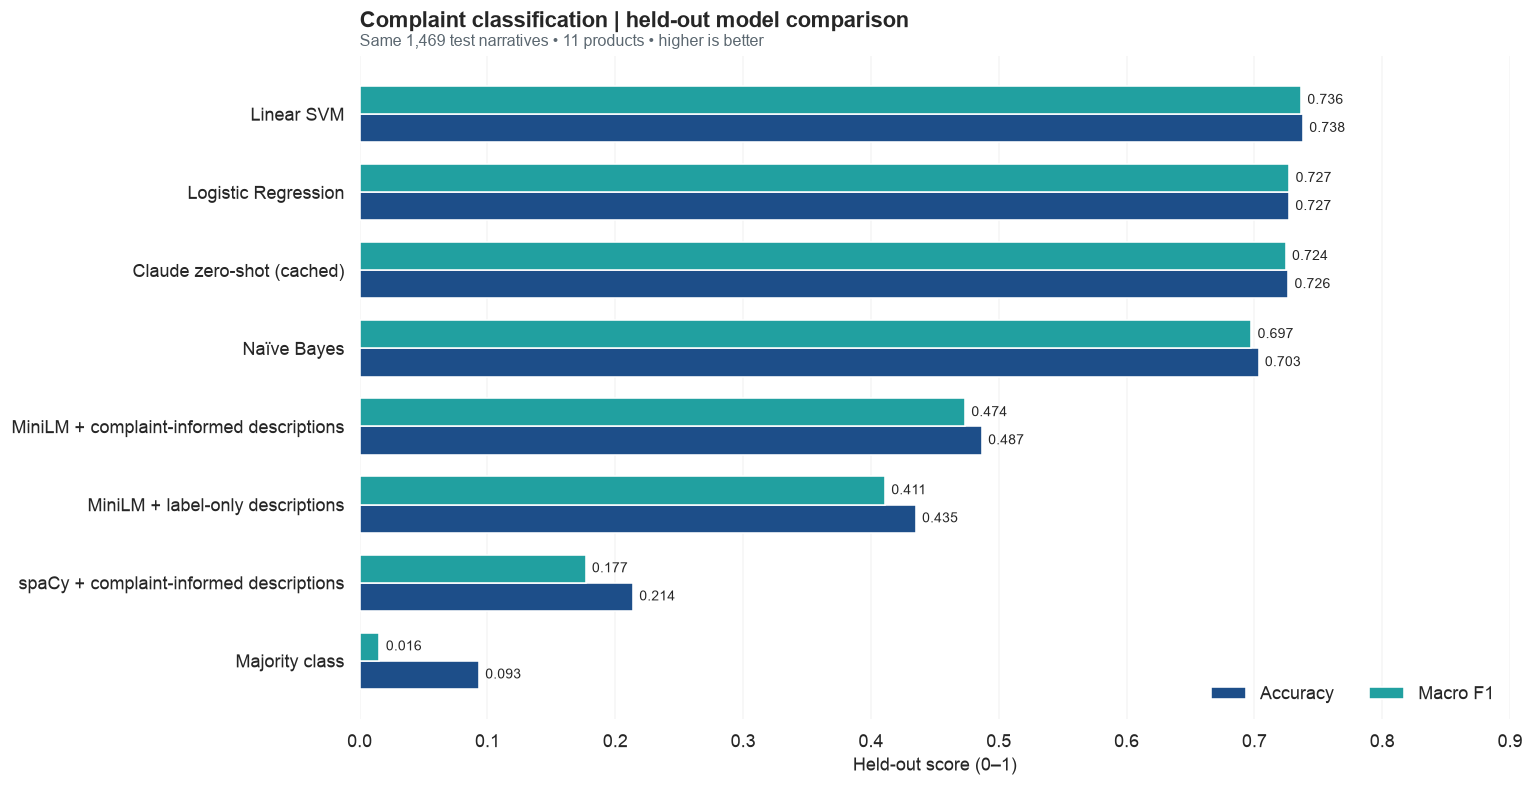

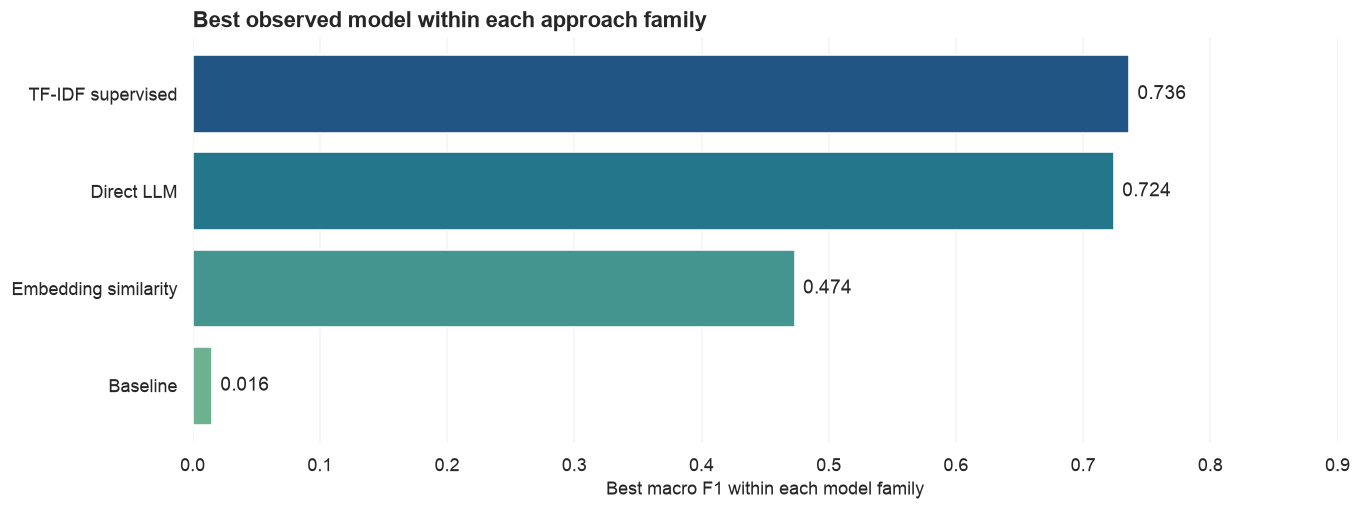

In [36]:
# PURPOSE: Summarize comparable held-out metrics and generate publication-ready charts.
# Evaluate every available approach on the same held-out complaint IDs.
# Consolidate all available methods into a common held-out results table.
results = pd.DataFrame(metrics_rows).set_index("Model").sort_values("Macro F1", ascending=False)
display(results.round(3))
results.to_csv(RESULTS_DIR / "unified_model_test_metrics.csv")

# Publication-style grouped bars with numeric labels and clear model-family distinctions.
# Rank models by macro F1 for a readable horizontal comparison.
plot_data = results.sort_values("Macro F1")
fig, ax = plt.subplots(figsize=(13.5, 7.0))
y = np.arange(len(plot_data))
height = 0.36
bars_acc = ax.barh(y - height / 2, plot_data["Accuracy"], height, color="#1D4E89", label="Accuracy")
bars_f1 = ax.barh(y + height / 2, plot_data["Macro F1"], height, color="#21A0A0", label="Macro F1")
ax.set_yticks(y, plot_data.index)
ax.set_xlim(0, 0.90)
ax.set_xlabel("Held-out score (0–1)")
ax.set_title("Complaint classification | held-out model comparison", loc="left", pad=18)
ax.text(0, 1.015, f"Same {len(y_test):,} test narratives • {len(labels)} products • higher is better",
        transform=ax.transAxes, fontsize=10, color="#5B6770")
ax.legend(loc="lower right", frameon=False, ncol=2)
ax.grid(axis="x", alpha=0.18)
ax.grid(axis="y", visible=False)
for bars in (bars_acc, bars_f1):
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "unified_model_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

# Compact visual showing how each model family compares with the majority baseline.
fig, ax = plt.subplots(figsize=(12, 4.6))
# Show the strongest observed result in each approach family.
family_plot = results.groupby("Family")["Macro F1"].max().sort_values()
family_bars = ax.barh(family_plot.index, family_plot.values, color=sns.color_palette("crest", n_colors=len(family_plot)))
ax.bar_label(family_bars, fmt="%.3f", padding=5)
ax.set(xlim=(0, 0.9), xlabel="Best macro F1 within each model family",
       title="Best observed model within each approach family")
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "best_model_by_family.png", dpi=220, bbox_inches="tight")
plt.show()

## 5. Classification errors and product-level performance

The **Linear SVM** was selected using training cross-validation (macro F1 ≈ **0.719**) and then evaluated on held-out complaints (**73.8% accuracy; 0.736 macro F1**). We examine per-product precision, recall, and F1, along with a confusion matrix and the most frequent wrong-product assignments. This matters because a strong overall accuracy can conceal important routing failures for individual teams.

**Observed pattern:** **Mortgage** has about **89.0% recall** and **Student loan** about **88.2%**, while **Debt or credit management** has the lowest recall, about **52.6%**. In other words, nearly half of that last category's test complaints were routed to a different product under this model. The confusion matrix identifies the specific destinations and should guide targeted error review; these are associations in the test sample, not proof of why a consumer used particular words.


Selected supervised model: Linear SVM


,precision,recall,f1-score,support
Checking or savings account,0.692,0.672,0.681,137.000
Credit card,0.671,0.691,0.681,136.000
Credit reporting or other personal consumer reports,0.714,0.882,0.789,119.000
Debt collection,0.688,0.683,0.685,126.000
Debt or credit management,0.703,0.526,0.602,135.000
"Money transfer, virtual currency, or money service",0.696,0.706,0.701,136.000
Mortgage,0.890,0.890,0.890,136.000
"Payday loan, title loan, personal loan, or advance loan",0.701,0.706,0.703,136.000
Prepaid card,0.669,0.713,0.690,136.000
Student loan,0.902,0.882,0.892,136.000


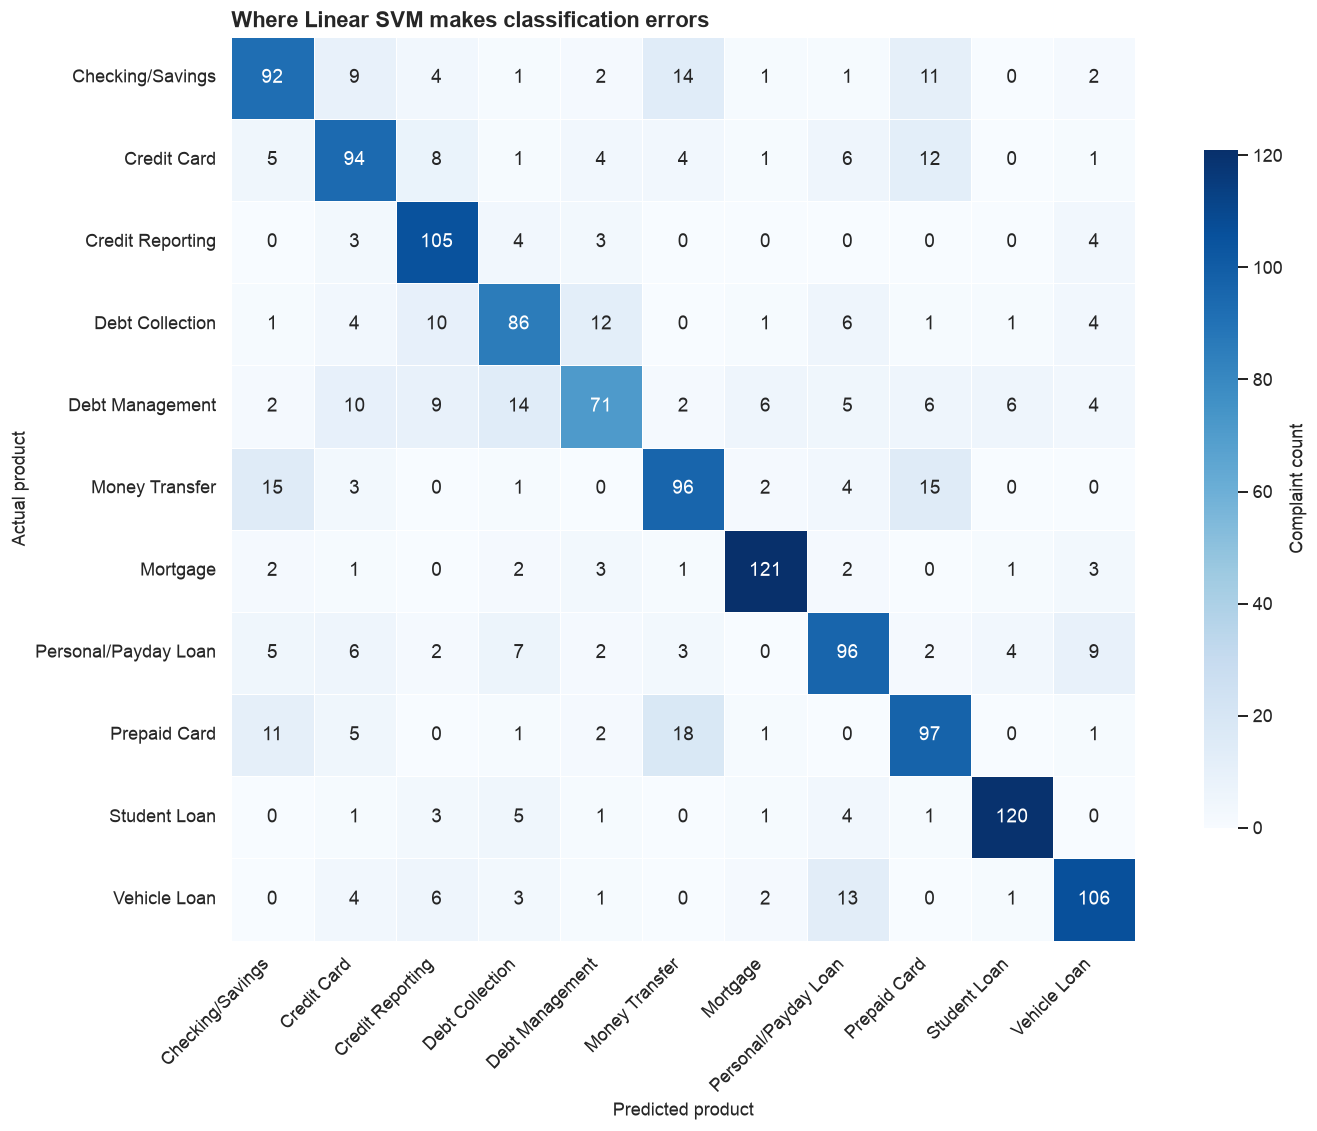

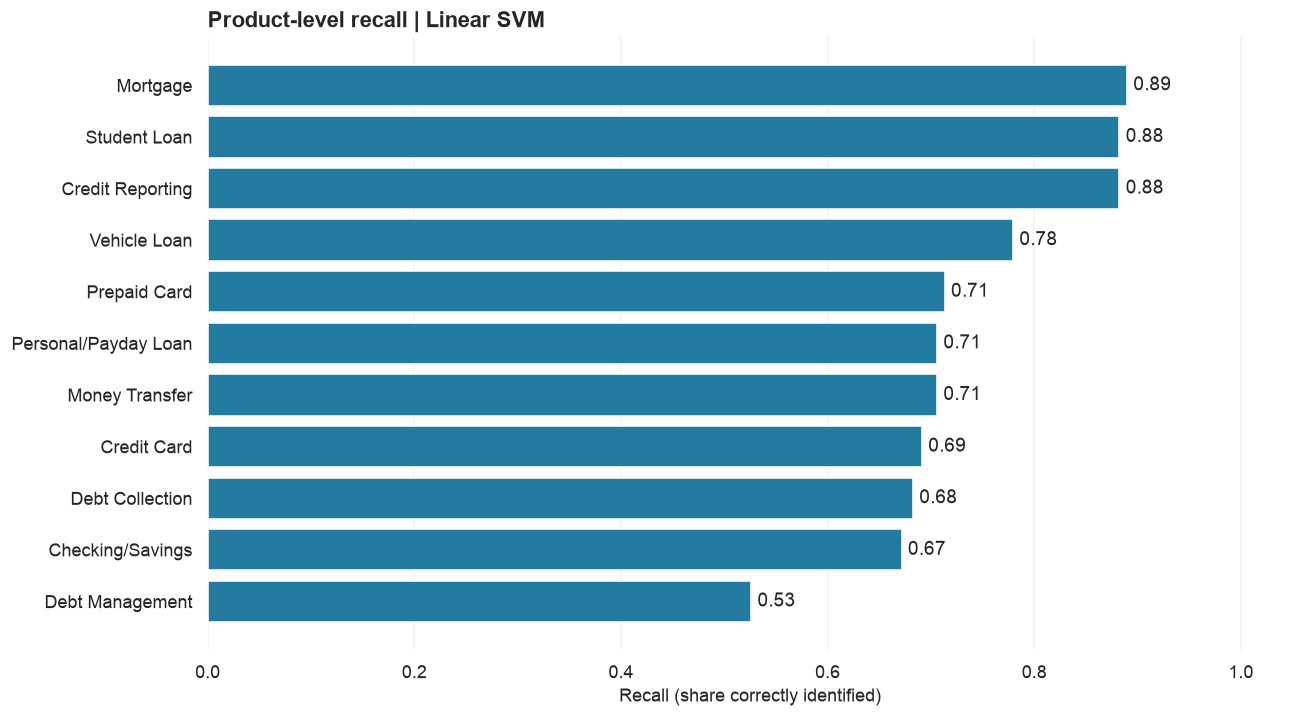

,Count,Actual product,Predicted product
0,18,Prepaid card,"Money transfer, virtual currency, or money service"
1,15,"Money transfer, virtual currency, or money service",Prepaid card
2,15,"Money transfer, virtual currency, or money service",Checking or savings account
3,14,Debt or credit management,Debt collection
4,14,Checking or savings account,"Money transfer, virtual currency, or money service"
5,13,Vehicle loan or lease,"Payday loan, title loan, personal loan, or advance loan"
6,12,Debt collection,Debt or credit management
7,12,Credit card,Prepaid card
8,11,Prepaid card,Checking or savings account
9,11,Checking or savings account,Prepaid card


In [37]:
# PURPOSE: Inspect product-level errors, confusion patterns, and recall for the selected SVM.
# Report per-product precision, recall, and F1 for the training-selected model.
selected_pred = predictions[selected_name]
print("Selected supervised model:", selected_name)
# Calculate one-vs-rest precision, recall and F1 for each product.
report = classification_report(y_test, selected_pred, labels=labels, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df.round(3))
report_df.to_csv(RESULTS_DIR / "selected_model_classification_report.csv")

# Use compact product names to avoid overlapping labels in the confusion matrix.
# Rows are actual products and columns are model predictions.
cm = confusion_matrix(y_test, selected_pred, labels=labels)
short_labels = [short_names.get(name, name) for name in labels]
fig, ax = plt.subplots(figsize=(13.5, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", linewidths=0.35, linecolor="white",
            xticklabels=short_labels, yticklabels=short_labels, square=True,
            cbar_kws={"label": "Complaint count", "shrink": 0.75}, ax=ax)
ax.set(xlabel="Predicted product", ylabel="Actual product", title=f"Where {selected_name} makes classification errors")
ax.tick_params(axis="x", labelrotation=45)
for tick in ax.get_xticklabels():
    tick.set_ha("right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "selected_model_confusion_matrix.png", dpi=220, bbox_inches="tight")
plt.show()

# Visualize class-level recall so weak categories are immediately visible.
per_class = report_df.loc[labels, ["precision", "recall", "f1-score", "support"]].copy()
per_class.index = [short_names.get(name, name) for name in labels]
per_class = per_class.sort_values("recall")
fig, ax = plt.subplots(figsize=(11.5, 6.4))
recall_bars = ax.barh(per_class.index, per_class["recall"], color="#247BA0")
ax.bar_label(recall_bars, fmt="%.2f", padding=4)
ax.set(xlim=(0, 1.05), xlabel="Recall (share correctly identified)",
       title=f"Product-level recall | {selected_name}")
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "selected_model_recall_by_product.png", dpi=220, bbox_inches="tight")
plt.show()

# List the most frequent off-diagonal classification errors.
# Exclude correct predictions to rank the most common routing mistakes.
confusions = sorted([(cm[i, j], labels[i], labels[j]) for i in range(len(labels))
                     for j in range(len(labels)) if i != j], reverse=True)
confusion_df = pd.DataFrame(confusions[:12], columns=["Count", "Actual product", "Predicted product"])
display(confusion_df)
confusion_df.to_csv(RESULTS_DIR / "top_misclassification_pairs.csv", index=False)

### 5.1 Precision, recall, and F1 by product

The grouped chart below makes **false-positive versus false-negative trade-offs** visible across product teams. **Precision** indicates how often a team's incoming complaints belong to it; **recall** indicates how many of its own complaints reach it. **F1** summarizes both. Focus first on the lowest-recall categories, where missed routing is most frequent.

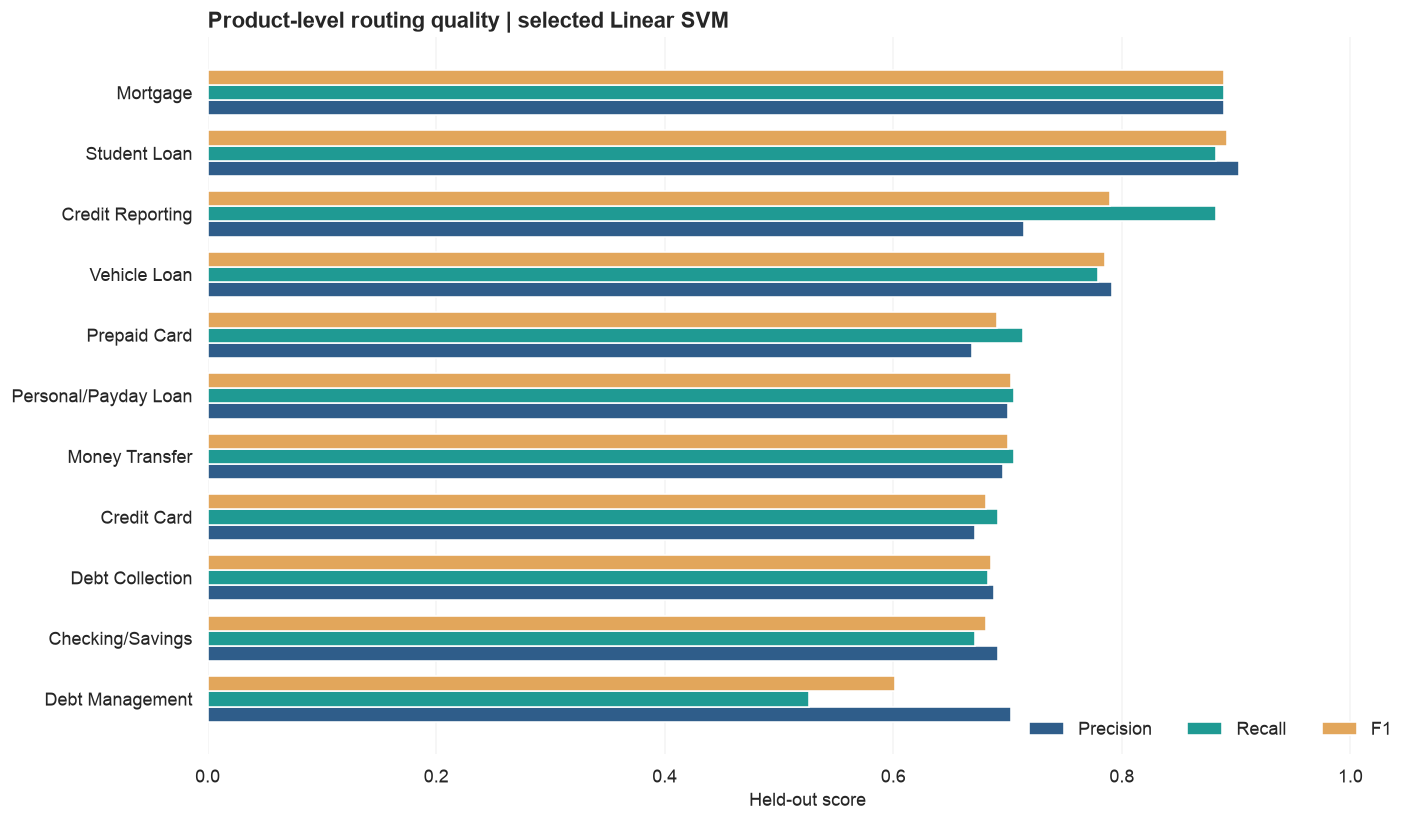

In [38]:
# PURPOSE: Compare per-product precision, recall, and F1 to reveal routing trade-offs.
# Extract only product rows from the existing classification report (exclude averages).
product_metrics = pd.DataFrame(report).T.loc[labels, ["precision", "recall", "f1-score"]].copy()
product_metrics = product_metrics.sort_values("recall")
fig, ax = plt.subplots(figsize=(12.5, 7.3))
positions = np.arange(len(product_metrics))
bar_width = 0.25
palette = ["#2F5D8A", "#1F9A93", "#E2A65B"]
for offset, metric, color in zip([-bar_width, 0, bar_width], product_metrics.columns, palette):
    ax.barh(positions + offset, product_metrics[metric], height=bar_width,
            label=metric.replace("f1-score", "F1" ).title(), color=color)
ax.set_yticks(positions, [short_names.get(name, name) for name in product_metrics.index])
ax.set(xlim=(0, 1.05), xlabel="Held-out score", title="Product-level routing quality | selected Linear SVM")
ax.legend(loc="lower right", frameon=False, ncol=3)
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "selected_model_product_precision_recall_f1.png", dpi=220, bbox_inches="tight")
plt.show()


## 6. Product-word masking robustness

A classifier may learn explicit product labels (such as “mortgage”) rather than broader descriptions of the underlying problem. We therefore mask a **predefined list of 15 product-identifying phrases** in **both the training and test narratives**, retrain the selected SVM pipeline, and compare its held-out results with the unmasked SVM. This is a **sensitivity test**, not proof of causal shortcut learning or a complete leakage audit: the dictionary is selective, and other product cues remain.

**Observed result:** **677 of 1,469** test narratives were changed by this dictionary. Macro F1 decreased from **0.736** to **0.721** (−**0.015**, or **1.5 percentage points**), and accuracy from **0.738** to **0.722** (−**0.016**). The limited decline suggests the model uses more than the explicitly masked phrases, but it does not rule out reliance on other lexical shortcuts.


,Condition,Accuracy,Macro F1
0,Original,0.738,0.736
1,Masked train and test,0.722,0.721


Test narratives affected: 677 of 1469


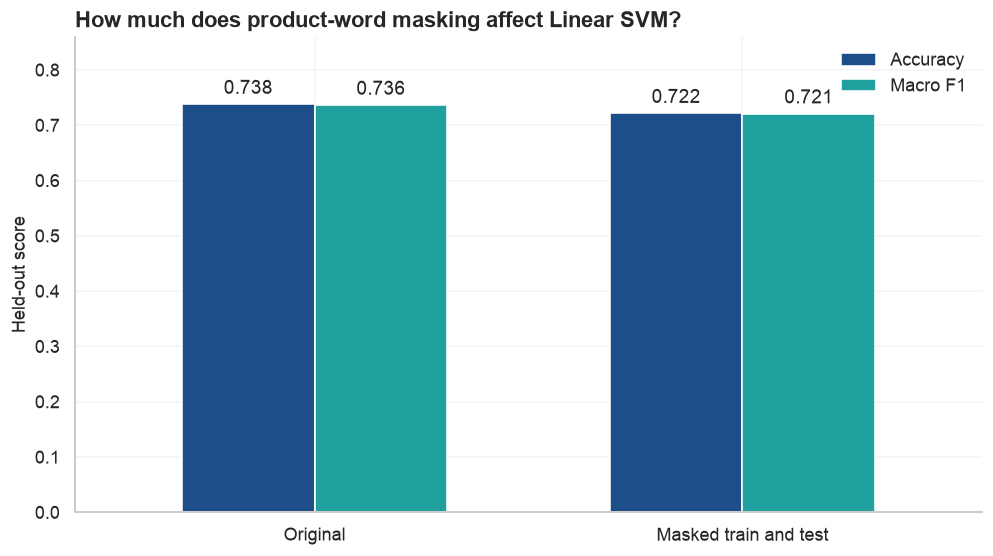

In [39]:
# PURPOSE: Retrain the selected pipeline after masking product terms in both splits.
# Explicit, auditable product terms (extend only with documented justification).
MASK_TERMS = ["mortgage", "credit card", "student loan", "vehicle loan", "auto loan", "checking account",
              "savings account", "debt collection", "credit reporting", "payday loan", "money transfer",
              "prepaid card", "personal loan", "bank account", "credit report"]
mask_pattern = re.compile(r"\b(?:" + "|".join(re.escape(w) for w in sorted(MASK_TERMS, key=len, reverse=True)) + r")\b", re.I)
# Helper: mask product terms for the analysis below.
def mask_product_terms(s):
    return mask_pattern.sub(" maskedproduct ", str(s))

masked_train = X_train.map(mask_product_terms)
masked_test = X_test.map(mask_product_terms)
masked_model = clone(selected_model).fit(masked_train, y_train)
# Apply the documented masking rule to both training and test text.
masked_pred = masked_model.predict(masked_test)
masking_table = pd.DataFrame([
    {"Condition": "Original", "Accuracy": accuracy_score(y_test, selected_pred),
     "Macro F1": f1_score(y_test, selected_pred, average="macro")},
    {"Condition": "Masked train and test", "Accuracy": accuracy_score(y_test, masked_pred),
     "Macro F1": f1_score(y_test, masked_pred, average="macro")}
])
display(masking_table.round(3))
print("Test narratives affected:", sum(X_test != masked_test), "of", len(X_test))
masking_table.to_csv(RESULTS_DIR / "unified_masking_results.csv", index=False)

# Show the size of the performance change, rather than relying on the table alone.
mask_plot = masking_table.set_index("Condition")[["Accuracy", "Macro F1"]]
ax = mask_plot.plot(kind="bar", figsize=(8.8, 5), width=0.62, color=["#1D4E89", "#21A0A0"], rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(ylim=(0, 0.86), xlabel="", ylabel="Held-out score", title="How much does product-word masking affect Linear SVM?")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "unified_masking_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## 7. Confidence-aware routing: operational feasibility

The training-selected **Linear SVM** produces decision scores, **not calibrated probabilities**. As an exploratory measure of prediction separation, we calculate the difference between the two highest class scores and divide held-out complaints into five equally sized groups. Larger gaps can indicate clearer model preferences, but the score scale does not directly represent a probability of correctness.

**Observed result:** Accuracy increases from approximately **43.5%** in the smallest-margin quintile to **98.0%** in the largest-margin quintile. This suggests that margins could help **prioritize manual review**, but the quintile boundaries and accuracies are **descriptive test-set results**, not deployment thresholds. Any production threshold must be selected using separate validation data, with calibration and ongoing monitoring.


,Margin group,Complaints,Accuracy,Median_margin
0,"(-0.0009337, 0.203]",294,0.435,0.082
1,"(0.203, 0.485]",294,0.609,0.329
2,"(0.485, 0.817]",293,0.778,0.645
3,"(0.817, 1.352]",294,0.888,1.050
4,"(1.352, 3.78]",294,0.980,1.716


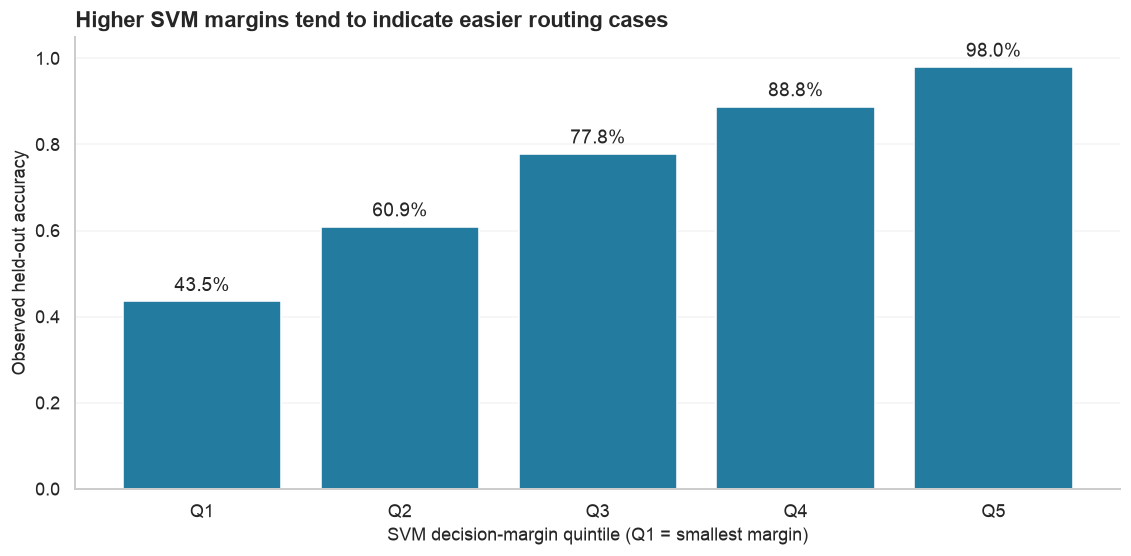

Descriptive only: do not use test-set quintiles as production thresholds.


In [40]:
# PURPOSE: Assess whether uncalibrated SVM margins rank cases by observed difficulty.
# Descriptive review-priority experiment: score margins are NOT probabilities.
if hasattr(selected_model, "decision_function"):
    # SVM decision scores are margins, not calibrated class probabilities.
    decision = np.asarray(selected_model.decision_function(X_test))
    top_two = np.sort(decision, axis=1)[:, -2:]
    margin = top_two[:, 1] - top_two[:, 0]
    correct = np.asarray(selected_pred) == y_test.to_numpy()
    margin_df = pd.DataFrame({"Margin": margin, "Correct": correct})
    # Group margins into equal-frequency bins for descriptive error-rate checks.
    margin_df["Margin group"] = pd.qcut(margin_df["Margin"], q=5, duplicates="drop")
    margin_summary = margin_df.groupby("Margin group", observed=True).agg(
        Complaints=("Correct", "size"), Accuracy=("Correct", "mean"),
        Median_margin=("Margin", "median")
    ).reset_index()
    display(margin_summary.round(3))
    margin_summary.to_csv(RESULTS_DIR / "svm_margin_review_descriptive.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(range(len(margin_summary)), margin_summary["Accuracy"], color="#247BA0")
    ax.bar_label(bars, fmt="%.1f", padding=4, labels=[f"{v:.1%}" for v in margin_summary["Accuracy"]])
    ax.set_xticks(range(len(margin_summary)), [f"Q{i+1}" for i in range(len(margin_summary))])
    ax.set(xlabel="SVM decision-margin quintile (Q1 = smallest margin)",
           ylabel="Observed held-out accuracy", ylim=(0, 1.05),
           title="Higher SVM margins tend to indicate easier routing cases")
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "svm_margin_vs_accuracy.png", dpi=220, bbox_inches="tight")
    plt.show()
    print("Descriptive only: do not use test-set quintiles as production thresholds.")
elif hasattr(selected_model, "predict_proba"):
    print("Probability-based routing needs validation-set calibration and threshold selection.")
else:
    print("No suitable score for review-priority analysis.")

### Interpretation: SVM Decision Margins and Classification Accuracy

The results show a strong positive relationship between SVM decision margins and classification accuracy. Accuracy increases consistently across the five quintiles, from **43.5% in Q1 (lowest margins)** to **98.0% in Q5 (highest margins)**.

This suggests that the model's decision margins can help distinguish relatively straightforward complaints from more ambiguous ones. Complaints with larger margins are more likely to be classified correctly, while those with smaller margins have a greater risk of being routed to the wrong financial product team.

**Business implication:** These findings support a human-in-the-loop complaint-routing system. Complaints with sufficiently large decision margins could be routed automatically, while those with smaller margins could be flagged for manual review. This approach could improve routing reliability and reduce unnecessary transfers between departments.

**Limitation:** SVM decision margins are not calibrated probabilities, and the observed accuracy rates are based on the held-out test sample. The quintiles are descriptive rather than validated operational thresholds. Before deployment, routing thresholds should be selected using separate validation data and evaluated on unseen complaints.

**Key takeaway:** The SVM model's decision margin provides useful information beyond overall classification accuracy and could help organizations balance automated complaint routing with human oversight.

## 8. Representativeness and subgroup checks

The source sample is approximately **balanced across product categories**, unlike actual CFPB complaint traffic. Overall accuracy in a live deployment may therefore differ if the product mix changes. We compare held-out accuracy across **submission channels** and **states**, displaying only groups with **at least 30 test complaints** to reduce very small-cell noise.

These are **descriptive operational subgroup comparisons**. They do not control for product mix, writing style, state-specific case mix, or other confounders; they do not establish bias, causality, or equal performance for demographic groups. A production fairness assessment would require an appropriate governance framework and additional validated data.


**Interpretive caution:** State-level differences can reflect small groups, product mix, writing styles, and other confounders. They should not be interpreted as causal evidence of geographic bias. The submission does not establish demographic fairness.

In [41]:
# PURPOSE: Summarize descriptive performance differences across sufficiently sized groups.
# Report group sizes and error rates for available, non-sensitive operational fields.
# Limit descriptive subgroup tables to groups with at least 30 test cases.
for field in ["Submitted via", "State"]:
    if field not in test_df.columns:
        continue
    tmp = pd.DataFrame({"Group": test_df[field].fillna("Unknown").astype(str),
                        "Correct": np.asarray(selected_pred) == y_test.to_numpy()})
    summary_group = tmp.groupby("Group").agg(n=("Correct", "size"), accuracy=("Correct", "mean"))
    summary_group = summary_group.loc[summary_group["n"] >= 30].sort_values("n", ascending=False)
    print(f"\n{field}: groups with at least 30 held-out complaints")
    display(summary_group.head(15).round(3))


Submitted via: groups with at least 30 held-out complaints


,n,accuracy
Group,,
Web,1469,0.738



State: groups with at least 30 held-out complaints


,n,accuracy
Group,,
CA,171,0.737
FL,159,0.748
TX,151,0.788
NY,87,0.724
GA,79,0.620
PA,58,0.741
NJ,51,0.765
IL,50,0.760
NC,49,0.776


## 9. Claude usage, privacy, and cost accounting

Claude played **three different roles** across the team's development work: (1) generating product descriptions from category labels alone, (2) generating complaint-informed product descriptions, and (3) directly classifying complaint narratives in zero-shot mode. **Only previously saved outputs are loaded here; this notebook makes no new Anthropic API requests.** The local spaCy/MiniLM similarity steps do not incur a per-complaint Claude inference fee.

The available **Ketty spend log totals $1.1400**, including any estimates recorded in that source. This is **not** a verified combined-team bill: Rebecca's historical description-generation token usage was not logged in this notebook, and provider-side billing has not been reconciled. Sending full narratives to an external API also raises privacy, access-control, retention, and data-governance considerations that do not arise in the same way when sending category labels only.


**Cost accounting boundary:** The spend log captures Ketty’s recorded/estimated activities; Rebecca’s historical description-generation token usage is not in this notebook. Consequently, the logged total is **not** the complete team API bill. Local compute time is also not a cloud operating-cost estimate.

In [42]:
# PURPOSE: Display the recorded Claude spend log without treating it as audited billing.
# Display the saved spend log; do not generate any new paid API requests.
if SPEND_CACHE.exists():
    spend = pd.read_csv(SPEND_CACHE)
    display(spend)
    if "cost_usd" in spend:
        print(f"Recorded Ketty spend-log total: ${pd.to_numeric(spend['cost_usd'], errors='coerce').sum():.4f}")
        print("Includes any estimated entries already recorded in the source log; not a verified team total.")
else:
    print("No spend log found. Exact historical API costs cannot be reconstructed from cached descriptions.")
print("No Claude API calls are executed by this unified notebook.")

,date,task,model,requests,input_tokens,output_tokens,cost_usd
0,2026-11-07 16:21,Product descriptions (k = 5),claude-sonnet-5-5,11,27331,3387,0.0885
1,2026-11-07 16:21,Product descriptions (k = 10),claude-sonnet-5-5,11,49860,3643,0.1361
2,2026-11-07 16:21,Product descriptions (k = 20),claude-sonnet-5-5,11,107603,3800,0.2532
3,2026-11-07 16:36,Zero-shot classification,claude-haiku-5-5,4895,1330950,20652,0.1434
4,2026-11-07 17:33,"Zero-shot failed requests (estimated, not logged at the time)",claude-haiku-5-5,2964,2042950,88920,0.2488
5,2026-11-07 17:37,Zero-shot classification,claude-haiku-5-5,2968,1932625,35273,0.2109
6,2026-11-07 17:49,Error analysis,claude-sonnet-5-5,428,0,0,0.0000
7,2026-11-07 17:58,Error analysis,claude-haiku-5-5,428,294484,59294,0.0591


Recorded Ketty spend-log total: $1.1400
Includes any estimated entries already recorded in the source log; not a verified team total.
No Claude API calls are executed by this unified notebook.


## 10. Conclusions and business recommendation

### 10.1 What the unified results show

- **Best supervised model:** Linear SVM, selected by **training five-fold cross-validation** (macro F1 **0.719**), achieved **73.8% held-out accuracy** and **0.736 macro F1** on 1,469 complaints. Logistic Regression was close (**72.7% accuracy; 0.727 macro F1**), followed by Naïve Bayes (**70.3%; 0.697**). The majority-class baseline achieved **9.3% accuracy**.
- **Claude zero-shot:** Cached, ID-aligned predictions achieved **72.6% accuracy and 0.724 macro F1**, including **16 missing/off-list responses counted as incorrect**. Performance was close to the leading supervised models, but the workflow requires sending narratives to an external API and incurs usage costs.
- **Embedding similarity:** MiniLM with complaint-informed descriptions achieved **48.7% accuracy / 0.474 macro F1**; MiniLM with label-only descriptions achieved **43.5% / 0.411**; spaCy with complaint-informed descriptions achieved **21.4% / 0.177**. These are **similarity-based classifiers**, not supervised fine-tuned embedding models. Description sources differ, so comparisons do not isolate a single causal factor.
- **Where the selected model struggles:** Debt or Credit Management has the lowest recall (**52.6%**), whereas Mortgage (**89.0%**) and Student Loan (**88.2%**) are classified more reliably. Several confusion pairs involve related financial products.
- **Vocabulary sensitivity:** Masking explicit product expressions in both train and test narratives reduced SVM macro F1 from **0.736 to 0.721**, a modest decline of 0.015 macro-F1 points (1.5 percentage points).

### 10.2 Practical recommendation

Use **locally executed Linear SVM with TF-IDF as the leading pilot candidate**, with a **human-review queue** for uncertain or high-impact cases. Do **not** treat uncalibrated SVM decision margins as probabilities; first calibrate scores and set review thresholds on validation data. Claude zero-shot may be useful as a carefully governed comparison or escalation option, subject to privacy, security, and cost approval. Monitor class-level recall—particularly Debt or Credit Management—rather than relying on overall accuracy alone.

### 10.3 Limitations

The sample is approximately class-balanced rather than representative of production traffic; narrative duplication was filtered, but text may contain redactions or template language. Reference descriptions and cached LLM predictions may have been generated under different prompts. The complaint IDs used to generate the cached reference descriptions were not retained here, so description-source overlap during training-only k selection cannot be independently excluded. The state comparisons are descriptive, no calibrated routing threshold was validated, and **no prospective production evaluation** was performed. All conclusions concern this held-out sample, not guaranteed real-world performance.

## 11. Reproducibility, data provenance, and limitations

**Files and environment.** Execute from the repository root or its `Notebook/` directory. The analysis reads `Data/cfpb_complaints_sample_2025-08_to_2026-07.csv`, project helpers under `src/`, and cached descriptions, zero-shot predictions, and spending logs. The initial setup cell contains all library imports. Optional embedding experiments require the spaCy `en_core_web_md` model and the `all-MiniLM-L6-v2` sentence-transformer weights.

**Evaluation protocol.** After removing exact duplicate narratives, the notebook creates one stratified 70/30 split (seed 42). Supervised classifiers are selected using five-fold training-only cross-validation and evaluated once on the holdout. The Claude predictions are matched by complaint ID; absent or off-list responses are counted as errors. Cached complaint-informed descriptions were created in earlier experiments, and their source complaint IDs are not available for independent verification; the description-size choice is therefore exploratory.

**Outputs.** Model metrics, classification reports, robustness tables, and charts are saved to `outputs/unified_analysis/`. The original individual notebooks remain development records; this notebook is the integrated group analysis.

**Interpretation limits.** The product-balanced sample does not reproduce the actual distribution of incoming complaints. Some narratives are redacted or templated, and no live routing workflow, independently validated confidence threshold, demographic fairness audit, or full team-wide API cost audit was conducted. Results should be interpreted as an offline comparison on the supplied CFPB sample.
